# Experiment 1 — Baseline CNN

The baseline CNN model is developed using the original PneumoniaMNIST dataset with basic preprocessing and pixel normalization. The model is trained to classify chest X-ray images into Normal and Pneumonia classes. Its performance is evaluated using accuracy, precision, recall, F1-score, AUC, confusion matrix, threshold analysis, and Grad-CAM explainability. These results will serve as the baseline for comparison with the image-processing-enhanced CNN developed in Experiment 2.

In [3]:
# ================================================================
# IMAGE PROCESSING - PNEUMONIA CLASSIFICATION
# ================================================================

import os
import time
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from PIL import Image

print("=" * 70)
print("IMAGE PROCESSING - PNEUMONIA CLASSIFICATION")
print("=" * 70)

print("\nLibraries imported successfully.")

IMAGE PROCESSING - PNEUMONIA CLASSIFICATION

Libraries imported successfully.


In [4]:
# ================================================================
# DATASET DISCOVERY
# ================================================================

print("=" * 70)
print("SEARCHING FOR IMAGE DATASET")
print("=" * 70)

# Project root
PROJECT_ROOT = os.path.abspath("..")

print(f"\nProject root: {PROJECT_ROOT}")

# Search for directories containing image files
image_extensions = (".jpg", ".jpeg", ".png", ".bmp", ".tif", ".tiff")

image_directories = []

for root, dirs, files in os.walk(PROJECT_ROOT):
    image_count = sum(
        1 for file in files
        if file.lower().endswith(image_extensions)
    )

    if image_count > 0:
        image_directories.append((root, image_count))

print("\nDirectories containing images:")
print("-" * 70)

if image_directories:
    for directory, count in image_directories:
        print(f"{count:6d} images | {directory}")
else:
    print("No image files found.")

SEARCHING FOR IMAGE DATASET

Project root: c:\Users\aquil\AI-Medical-Diagnosis-Platform

Directories containing images:
----------------------------------------------------------------------
     2 images | c:\Users\aquil\AI-Medical-Diagnosis-Platform\aipp\Lib\site-packages\ipykernel\resources
     2 images | c:\Users\aquil\AI-Medical-Diagnosis-Platform\aipp\Lib\site-packages\IPython\core\tests
    21 images | c:\Users\aquil\AI-Medical-Diagnosis-Platform\aipp\Lib\site-packages\matplotlib\mpl-data\images
     3 images | c:\Users\aquil\AI-Medical-Diagnosis-Platform\aipp\Lib\site-packages\matplotlib\mpl-data\sample_data
     1 images | c:\Users\aquil\AI-Medical-Diagnosis-Platform\aipp\Lib\site-packages\networkx\drawing\tests\baseline
     1 images | c:\Users\aquil\AI-Medical-Diagnosis-Platform\aipp\Lib\site-packages\scipy\ndimage\tests
     1 images | c:\Users\aquil\AI-Medical-Diagnosis-Platform\aipp\Lib\site-packages\shap\plots\resources
    28 images | c:\Users\aquil\AI-Medical-Diagnosi

In [5]:
# ================================================================
# LOAD PNEUMONIAMNIST DATASET
# ================================================================

print("=" * 70)
print("LOADING PNEUMONIAMNIST DATASET")
print("=" * 70)

DATASET_PATH = os.path.join(
    PROJECT_ROOT,
    "datasets",
    "image",
    "pneumoniamnist",
    "pneumoniamnist.npz"
)

print(f"\nDataset path: {DATASET_PATH}")

# Check whether dataset exists
if not os.path.exists(DATASET_PATH):
    raise FileNotFoundError(
        f"PneumoniaMNIST dataset not found:\n{DATASET_PATH}"
    )

# Load NPZ dataset
data = np.load(DATASET_PATH)

print("\nDataset loaded successfully.")

# Show available arrays
print("\nAvailable arrays:")
for key in data.files:
    print(f"  {key}: {data[key].shape}")

print("\n" + "=" * 70)
print("DATASET SPLITS")
print("=" * 70)

for split in ["train", "val", "test"]:
    if f"{split}_images" in data.files:
        print(
            f"{split.upper():5s} images: "
            f"{data[f'{split}_images'].shape}"
        )

    if f"{split}_labels" in data.files:
        print(
            f"{split.upper():5s} labels: "
            f"{data[f'{split}_labels'].shape}"
        )

LOADING PNEUMONIAMNIST DATASET

Dataset path: c:\Users\aquil\AI-Medical-Diagnosis-Platform\datasets\image\pneumoniamnist\pneumoniamnist.npz

Dataset loaded successfully.

Available arrays:
  train_images: (4708, 28, 28)
  val_images: (524, 28, 28)
  test_images: (624, 28, 28)
  train_labels: (4708, 1)
  val_labels: (524, 1)
  test_labels: (624, 1)

DATASET SPLITS
TRAIN images: (4708, 28, 28)
TRAIN labels: (4708, 1)
VAL   images: (524, 28, 28)
VAL   labels: (524, 1)
TEST  images: (624, 28, 28)
TEST  labels: (624, 1)


In [6]:
# ================================================================
# CLASS DISTRIBUTION
# ================================================================

print("=" * 70)
print("PNEUMONIAMNIST CLASS DISTRIBUTION")
print("=" * 70)

# Extract labels
y_train = data["train_labels"].ravel()
y_val = data["val_labels"].ravel()
y_test = data["test_labels"].ravel()

# Class names
class_names = {
    0: "Normal",
    1: "Pneumonia"
}

# Function to display distribution
def display_distribution(labels, split_name):
    counts = pd.Series(labels).value_counts().sort_index()
    percentages = counts / len(labels) * 100

    distribution = pd.DataFrame({
        "Class": [class_names[int(i)] for i in counts.index],
        "Count": counts.values,
        "Percentage": percentages.values
    })

    print(f"\n{split_name}")
    print("-" * 70)
    print(distribution.to_string(index=False))

    return distribution


train_distribution = display_distribution(
    y_train,
    "TRAINING SET"
)

val_distribution = display_distribution(
    y_val,
    "VALIDATION SET"
)

test_distribution = display_distribution(
    y_test,
    "TEST SET"
)

PNEUMONIAMNIST CLASS DISTRIBUTION

TRAINING SET
----------------------------------------------------------------------
    Class  Count  Percentage
   Normal   1214   25.785896
Pneumonia   3494   74.214104

VALIDATION SET
----------------------------------------------------------------------
    Class  Count  Percentage
   Normal    135   25.763359
Pneumonia    389   74.236641

TEST SET
----------------------------------------------------------------------
    Class  Count  Percentage
   Normal    234        37.5
Pneumonia    390        62.5


In [7]:
# ================================================================
# IMAGE STATISTICS
# ================================================================

print("=" * 70)
print("PNEUMONIAMNIST IMAGE STATISTICS")
print("=" * 70)

# Extract image arrays
X_train = data["train_images"]
X_val = data["val_images"]
X_test = data["test_images"]

print("\nImage shapes:")
print(f"Training   : {X_train.shape}")
print(f"Validation : {X_val.shape}")
print(f"Testing    : {X_test.shape}")

print("\nData types:")
print(f"Training   : {X_train.dtype}")
print(f"Validation : {X_val.dtype}")
print(f"Testing    : {X_test.dtype}")

print("\nPixel value ranges:")
print(
    f"Training   : min={X_train.min()}, "
    f"max={X_train.max()}"
)
print(
    f"Validation : min={X_val.min()}, "
    f"max={X_val.max()}"
)
print(
    f"Testing    : min={X_test.min()}, "
    f"max={X_test.max()}"
)

print("\nPixel statistics - Training set:")
print(f"Mean       : {X_train.mean():.4f}")
print(f"Std        : {X_train.std():.4f}")
print(f"Median     : {np.median(X_train):.4f}")

print("\nUnique pixel values:")
print(f"Number of unique values: {len(np.unique(X_train))}")

print("\nMemory usage:")
print(f"Training   : {X_train.nbytes / (1024 ** 2):.2f} MB")
print(f"Validation : {X_val.nbytes / (1024 ** 2):.2f} MB")
print(f"Testing    : {X_test.nbytes / (1024 ** 2):.2f} MB")

PNEUMONIAMNIST IMAGE STATISTICS

Image shapes:
Training   : (4708, 28, 28)
Validation : (524, 28, 28)
Testing    : (624, 28, 28)

Data types:
Training   : uint8
Validation : uint8
Testing    : uint8

Pixel value ranges:
Training   : min=0, max=255
Validation : min=0, max=255
Testing    : min=0, max=254

Pixel statistics - Training set:
Mean       : 145.8400
Std        : 42.9296
Median     : 153.0000

Unique pixel values:
Number of unique values: 256

Memory usage:
Training   : 3.52 MB
Validation : 0.39 MB
Testing    : 0.47 MB


SAMPLE PNEUMONIAMNIST X-RAY IMAGES


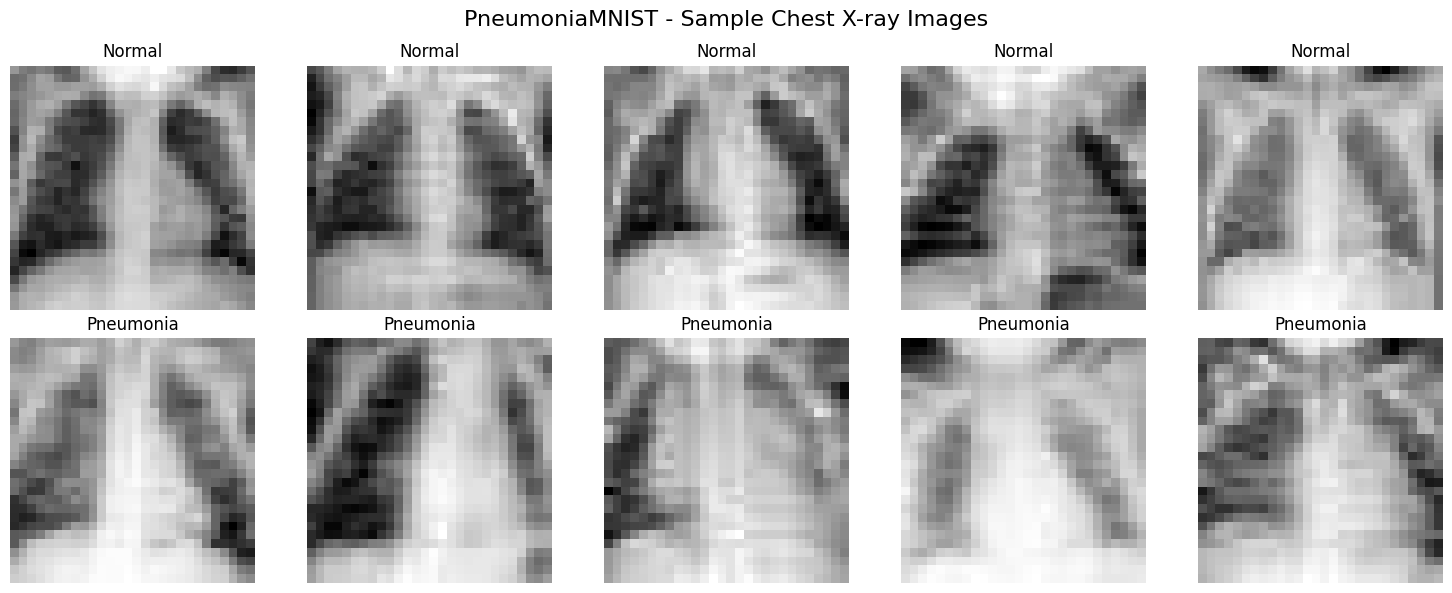

In [8]:
# ================================================================
# VISUALIZE SAMPLE X-RAY IMAGES
# ================================================================

print("=" * 70)
print("SAMPLE PNEUMONIAMNIST X-RAY IMAGES")
print("=" * 70)

# Find sample indices for each class
normal_indices = np.where(y_train == 0)[0]
pneumonia_indices = np.where(y_train == 1)[0]

# Select 5 samples from each class
np.random.seed(42)

normal_samples = np.random.choice(
    normal_indices,
    size=5,
    replace=False
)

pneumonia_samples = np.random.choice(
    pneumonia_indices,
    size=5,
    replace=False
)

# Create visualization
fig, axes = plt.subplots(
    2,
    5,
    figsize=(15, 6)
)

# Normal images
for i, idx in enumerate(normal_samples):
    axes[0, i].imshow(
        X_train[idx],
        cmap="gray"
    )
    axes[0, i].set_title("Normal")
    axes[0, i].axis("off")

# Pneumonia images
for i, idx in enumerate(pneumonia_samples):
    axes[1, i].imshow(
        X_train[idx],
        cmap="gray"
    )
    axes[1, i].set_title("Pneumonia")
    axes[1, i].axis("off")

plt.suptitle(
    "PneumoniaMNIST - Sample Chest X-ray Images",
    fontsize=16
)

plt.tight_layout()
plt.show()

In [9]:
# ================================================================
# IMAGE PREPROCESSING
# ================================================================

print("=" * 70)
print("IMAGE PREPROCESSING")
print("=" * 70)

# Convert pixel values from uint8 to float32
X_train_processed = X_train.astype("float32")
X_val_processed = X_val.astype("float32")
X_test_processed = X_test.astype("float32")

# Normalize pixel values from [0, 255] to [0, 1]
X_train_processed /= 255.0
X_val_processed /= 255.0
X_test_processed /= 255.0

# Add channel dimension for CNN
X_train_processed = np.expand_dims(X_train_processed, axis=-1)
X_val_processed = np.expand_dims(X_val_processed, axis=-1)
X_test_processed = np.expand_dims(X_test_processed, axis=-1)

print("\nPreprocessing completed successfully.")

print("\nProcessed shapes:")
print(f"Training   : {X_train_processed.shape}")
print(f"Validation : {X_val_processed.shape}")
print(f"Testing    : {X_test_processed.shape}")

print("\nProcessed data types:")
print(f"Training   : {X_train_processed.dtype}")

print("\nNormalized pixel range:")
print(
    f"Training   : "
    f"min={X_train_processed.min():.4f}, "
    f"max={X_train_processed.max():.4f}"
)

print("\nProcessed training statistics:")
print(f"Mean : {X_train_processed.mean():.4f}")
print(f"Std  : {X_train_processed.std():.4f}")

IMAGE PREPROCESSING

Preprocessing completed successfully.

Processed shapes:
Training   : (4708, 28, 28, 1)
Validation : (524, 28, 28, 1)
Testing    : (624, 28, 28, 1)

Processed data types:
Training   : float32

Normalized pixel range:
Training   : min=0.0000, max=1.0000

Processed training statistics:
Mean : 0.5719
Std  : 0.1684


In [10]:
# ================================================================
# CLASS WEIGHTS FOR IMBALANCED DATA
# ================================================================

from sklearn.utils.class_weight import compute_class_weight

print("=" * 70)
print("CLASS WEIGHTS")
print("=" * 70)

# Flatten labels
y_train_flat = np.asarray(y_train).ravel()

# Get unique classes
classes = np.unique(y_train_flat)

# Calculate balanced class weights
class_weights_values = compute_class_weight(
    class_weight="balanced",
    classes=classes,
    y=y_train_flat
)

# Create dictionary for model training
class_weights = {
    int(cls): float(weight)
    for cls, weight in zip(classes, class_weights_values)
}

print("\nClass distribution:")
for cls in classes:
    count = np.sum(y_train_flat == cls)
    percentage = (count / len(y_train_flat)) * 100

    print(
        f"Class {int(cls)}: "
        f"{count} images "
        f"({percentage:.2f}%)"
    )

print("\nCalculated class weights:")

for cls, weight in class_weights.items():
    class_name = "Normal" if cls == 0 else "Pneumonia"

    print(
        f"Class {cls} ({class_name}): "
        f"{weight:.4f}"
    )

CLASS WEIGHTS

Class distribution:
Class 0: 1214 images (25.79%)
Class 1: 3494 images (74.21%)

Calculated class weights:
Class 0 (Normal): 1.9390
Class 1 (Pneumonia): 0.6737


In [11]:
# ================================================================
# TENSORFLOW / KERAS VERIFICATION
# ================================================================

import tensorflow as tf
from tensorflow import keras

print("=" * 70)
print("TENSORFLOW ENVIRONMENT")
print("=" * 70)

print(f"TensorFlow version : {tf.__version__}")
print(f"Keras version      : {keras.__version__}")

print("\nAvailable devices:")
for device in tf.config.list_physical_devices():
    print(f"  {device.device_type}: {device.name}")

print("\nTensorFlow environment ready.")

TENSORFLOW ENVIRONMENT
TensorFlow version : 2.21.0
Keras version      : 3.12.4

Available devices:
  CPU: /physical_device:CPU:0

TensorFlow environment ready.


In [12]:
# ================================================================
# CNN MODEL ARCHITECTURE
# ================================================================

import tensorflow as tf
from tensorflow import keras
from tensorflow.keras import layers

print("=" * 70)
print("CNN MODEL ARCHITECTURE")
print("=" * 70)

# Create CNN model
cnn_model = keras.Sequential([
    
    # Input
    layers.Input(shape=(28, 28, 1)),

    # Convolution Block 1
    layers.Conv2D(
        32,
        kernel_size=(3, 3),
        activation="relu",
        padding="same"
    ),
    layers.MaxPooling2D(pool_size=(2, 2)),

    # Convolution Block 2
    layers.Conv2D(
        64,
        kernel_size=(3, 3),
        activation="relu",
        padding="same"
    ),
    layers.MaxPooling2D(pool_size=(2, 2)),

    # Convolution Block 3
    layers.Conv2D(
        128,
        kernel_size=(3, 3),
        activation="relu",
        padding="same"
    ),
    layers.MaxPooling2D(pool_size=(2, 2)),

    # Flatten
    layers.Flatten(),

    # Fully Connected Layer
    layers.Dense(128, activation="relu"),

    # Dropout
    layers.Dropout(0.5),

    # Output Layer
    layers.Dense(1, activation="sigmoid")
])

# Display architecture
cnn_model.summary()

CNN MODEL ARCHITECTURE


Model: "sequential"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ conv2d (Conv2D)                 │ (None, 28, 28, 32)     │           320 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d (MaxPooling2D)    │ (None, 14, 14, 32)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_1 (Conv2D)               │ (None, 14, 14, 64)     │        18,496 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_1 (MaxPooling2D)  │ (None, 7, 7, 64)       │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_2 (Conv2D)               │ (None, 7, 7, 128)      │        73,856 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_2 (MaxPooling2D)  │ (None, 3, 3, 128)      │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ flatten (Flatten)               │ (None, 1152)           │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense (Dense)                   │ (None, 128)            │       147,584 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout (Dropout)               │ (None, 128)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 1)              │           129 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 240,385 (939.00 KB)

 Trainable params: 240,385 (939.00 KB)

 Non-trainable params: 0 (0.00 B)

In [13]:
# ================================================================
# CNN MODEL COMPILATION
# ================================================================

print("=" * 70)
print("CNN MODEL COMPILATION")
print("=" * 70)

cnn_model.compile(
    optimizer=keras.optimizers.Adam(learning_rate=0.001),
    loss="binary_crossentropy",
    metrics=[
        keras.metrics.BinaryAccuracy(name="accuracy"),
        keras.metrics.Precision(name="precision"),
        keras.metrics.Recall(name="recall"),
        keras.metrics.AUC(name="auc")
    ]
)

print("\nCNN model compiled successfully.")

print("\nLoss function      : Binary Cross-Entropy")
print("Optimizer          : Adam")
print("Learning rate      : 0.001")
print("Metrics            : Accuracy, Precision, Recall, AUC")

CNN MODEL COMPILATION

CNN model compiled successfully.

Loss function      : Binary Cross-Entropy
Optimizer          : Adam
Learning rate      : 0.001
Metrics            : Accuracy, Precision, Recall, AUC


In [14]:
# ================================================================
# CNN TRAINING CALLBACKS
# ================================================================

from tensorflow.keras.callbacks import (
    EarlyStopping,
    ModelCheckpoint,
    ReduceLROnPlateau
)

print("=" * 70)
print("CNN TRAINING CALLBACKS")
print("=" * 70)

# Stop training when validation loss stops improving
early_stopping = EarlyStopping(
    monitor="val_loss",
    patience=5,
    restore_best_weights=True,
    verbose=1
)

# Save the best model during training
checkpoint_path = "../models/image_pneumonia_cnn_best.keras"

model_checkpoint = ModelCheckpoint(
    checkpoint_path,
    monitor="val_loss",
    save_best_only=True,
    verbose=1
)

# Reduce learning rate when validation loss plateaus
reduce_lr = ReduceLROnPlateau(
    monitor="val_loss",
    factor=0.5,
    patience=2,
    min_lr=1e-6,
    verbose=1
)

callbacks = [
    early_stopping,
    model_checkpoint,
    reduce_lr
]

print("\nCallbacks configured successfully.")
print("Early stopping patience : 5 epochs")
print("LR reduction factor     : 0.5")
print("Best model path         :", checkpoint_path)

CNN TRAINING CALLBACKS

Callbacks configured successfully.
Early stopping patience : 5 epochs
LR reduction factor     : 0.5
Best model path         : ../models/image_pneumonia_cnn_best.keras


In [15]:
print([name for name in globals() if "train" in name.lower()])
print([name for name in globals() if "val" in name.lower()])

['y_train', 'train_distribution', 'X_train', 'X_train_processed', 'y_train_flat']
['y_val', 'val_distribution', 'X_val', 'X_val_processed', 'class_weights_values']


In [16]:
print("Class weights:", class_weights_values)
print("X_train_processed:", X_train_processed.shape)
print("y_train:", y_train.shape)
print("X_val_processed:", X_val_processed.shape)
print("y_val:", y_val.shape)

Class weights: [1.93904448 0.67372639]
X_train_processed: (4708, 28, 28, 1)
y_train: (4708,)
X_val_processed: (524, 28, 28, 1)
y_val: (524,)


In [17]:
# ================================================================
# PREPARE CLASS WEIGHTS FOR CNN TRAINING
# ================================================================

class_weights = {
    0: float(class_weights_values[0]),  # Normal
    1: float(class_weights_values[1])   # Pneumonia
}

print("=" * 70)
print("CNN CLASS WEIGHTS")
print("=" * 70)

print(f"Class 0 (Normal)    : {class_weights[0]:.4f}")
print(f"Class 1 (Pneumonia) : {class_weights[1]:.4f}")

CNN CLASS WEIGHTS
Class 0 (Normal)    : 1.9390
Class 1 (Pneumonia) : 0.6737


In [18]:
# ================================================================
# CNN MODEL TRAINING
# ================================================================

print("=" * 70)
print("CNN TRAINING")
print("=" * 70)

start_time = time.time()

history = cnn_model.fit(
    X_train_processed,
    y_train,
    validation_data=(X_val_processed, y_val),
    epochs=30,
    batch_size=32,
    class_weight=class_weights,
    callbacks=callbacks,
    verbose=1
)

training_time = time.time() - start_time

print("\n" + "=" * 70)
print("CNN TRAINING COMPLETED")
print("=" * 70)

print(f"Training time : {training_time:.2f} seconds")
print(f"Epochs run    : {len(history.history['loss'])}")

CNN TRAINING
Epoch 1/30
148/148 ━━━━━━━━━━━━━━━━━━━━ 0s 10ms/step - accuracy: 0.6551 - auc: 0.7309 - loss: 0.5693 - precision: 0.8579 - recall: 0.6472
Epoch 1: val_loss improved from None to 0.16335, saving model to ../models/image_pneumonia_cnn_best.keras
148/148 ━━━━━━━━━━━━━━━━━━━━ 4s 14ms/step - accuracy: 0.7744 - auc: 0.8892 - loss: 0.4172 - precision: 0.9225 - recall: 0.7599 - val_accuracy: 0.9427 - val_auc: 0.9855 - val_loss: 0.1634 - val_precision: 0.9812 - val_recall: 0.9409 - learning_rate: 0.0010
Epoch 2/30
147/148 ━━━━━━━━━━━━━━━━━━━━ 0s 10ms/step - accuracy: 0.9169 - auc: 0.9694 - loss: 0.2203 - precision: 0.9714 - recall: 0.9147
Epoch 2: val_loss did not improve from 0.16335
148/148 ━━━━━━━━━━━━━━━━━━━━ 2s 11ms/step - accuracy: 0.9288 - auc: 0.9765 - loss: 0.1905 - precision: 0.9791 - recall: 0.9239 - val_accuracy: 0.9275 - val_auc: 0.9896 - val_loss: 0.1780 - val_precision: 0.9889 - val_recall: 0.9126 - learning_rate: 0.0010
Epoch 3/30
147/148 ━━━━━━━━━━━━━━━━━━━━ 0s 10m

In [19]:
# ================================================================
# CNN TEST SET EVALUATION
# ================================================================

from tensorflow import keras
from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    roc_auc_score,
    confusion_matrix,
    classification_report
)
import numpy as np

print("=" * 70)
print("EVALUATION: CNN - PNEUMONIA CLASSIFICATION")
print("=" * 70)

# Load the best saved model
best_cnn_model = keras.models.load_model(
    "../models/image_pneumonia_cnn_best.keras"
)

# Predict probabilities
y_test_prob = best_cnn_model.predict(
    X_test_processed,
    verbose=0
).ravel()

# Convert probabilities to class predictions
y_test_pred = (y_test_prob >= 0.5).astype(int)

# Calculate metrics
test_accuracy = accuracy_score(y_test, y_test_pred)
test_precision = precision_score(y_test, y_test_pred, zero_division=0)
test_recall = recall_score(y_test, y_test_pred, zero_division=0)
test_f1 = f1_score(y_test, y_test_pred, zero_division=0)
test_auc = roc_auc_score(y_test, y_test_prob)

# Confusion matrix
cm = confusion_matrix(y_test, y_test_pred)

print(f"\nAccuracy  : {test_accuracy:.4f}")
print(f"Precision : {test_precision:.4f}")
print(f"Recall    : {test_recall:.4f}")
print(f"F1 Score  : {test_f1:.4f}")
print(f"AUC       : {test_auc:.4f}")

print("\nConfusion Matrix:")
print(cm)

print("\nClassification Report:")
print(
    classification_report(
        y_test,
        y_test_pred,
        target_names=["Normal", "Pneumonia"],
        digits=4
    )
)

EVALUATION: CNN - PNEUMONIA CLASSIFICATION

Accuracy  : 0.8718
Precision : 0.8444
Recall    : 0.9744
F1 Score  : 0.9048
AUC       : 0.9428

Confusion Matrix:
[[164  70]
 [ 10 380]]

Classification Report:
              precision    recall  f1-score   support

      Normal     0.9425    0.7009    0.8039       234
   Pneumonia     0.8444    0.9744    0.9048       390

    accuracy                         0.8718       624
   macro avg     0.8935    0.8376    0.8543       624
weighted avg     0.8812    0.8718    0.8669       624



CNN TRAINING HISTORY


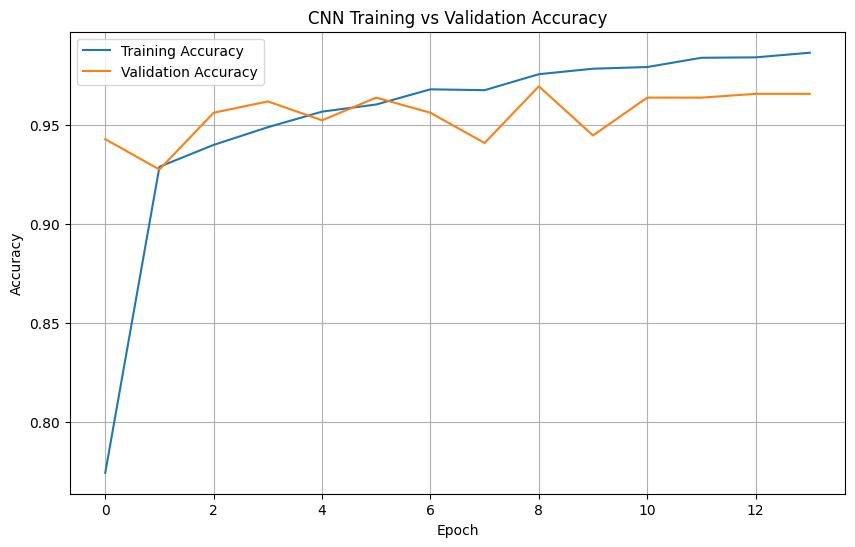

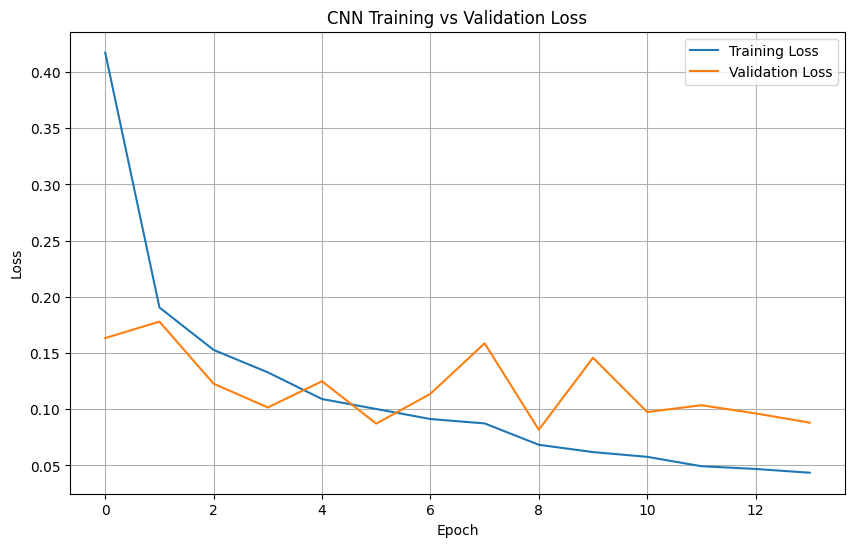

In [20]:
# ================================================================
# CNN TRAINING HISTORY
# ================================================================

import matplotlib.pyplot as plt

print("=" * 70)
print("CNN TRAINING HISTORY")
print("=" * 70)

history_dict = history.history

plt.figure(figsize=(10, 6))

plt.plot(
    history_dict["accuracy"],
    label="Training Accuracy"
)

plt.plot(
    history_dict["val_accuracy"],
    label="Validation Accuracy"
)

plt.xlabel("Epoch")
plt.ylabel("Accuracy")
plt.title("CNN Training vs Validation Accuracy")
plt.legend()
plt.grid(True)

plt.show()


plt.figure(figsize=(10, 6))

plt.plot(
    history_dict["loss"],
    label="Training Loss"
)

plt.plot(
    history_dict["val_loss"],
    label="Validation Loss"
)

plt.xlabel("Epoch")
plt.ylabel("Loss")
plt.title("CNN Training vs Validation Loss")
plt.legend()
plt.grid(True)

plt.show()

CNN CONFUSION MATRIX

Confusion Matrix:
[[164  70]
 [ 10 380]]


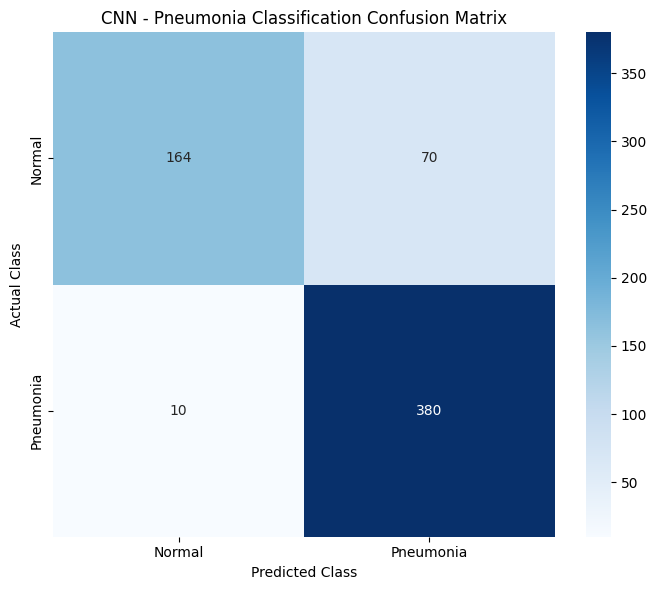

In [21]:
# ================================================================
# CNN CONFUSION MATRIX
# ================================================================

import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.metrics import confusion_matrix

print("=" * 70)
print("CNN CONFUSION MATRIX")
print("=" * 70)

# Create confusion matrix
cm = confusion_matrix(y_test, y_test_pred)

print("\nConfusion Matrix:")
print(cm)

# Plot
plt.figure(figsize=(7, 6))

sns.heatmap(
    cm,
    annot=True,
    fmt="d",
    cmap="Blues",
    xticklabels=["Normal", "Pneumonia"],
    yticklabels=["Normal", "Pneumonia"]
)

plt.xlabel("Predicted Class")
plt.ylabel("Actual Class")
plt.title("CNN - Pneumonia Classification Confusion Matrix")

plt.tight_layout()
plt.show()

CNN ROC CURVE

ROC-AUC: 0.9428


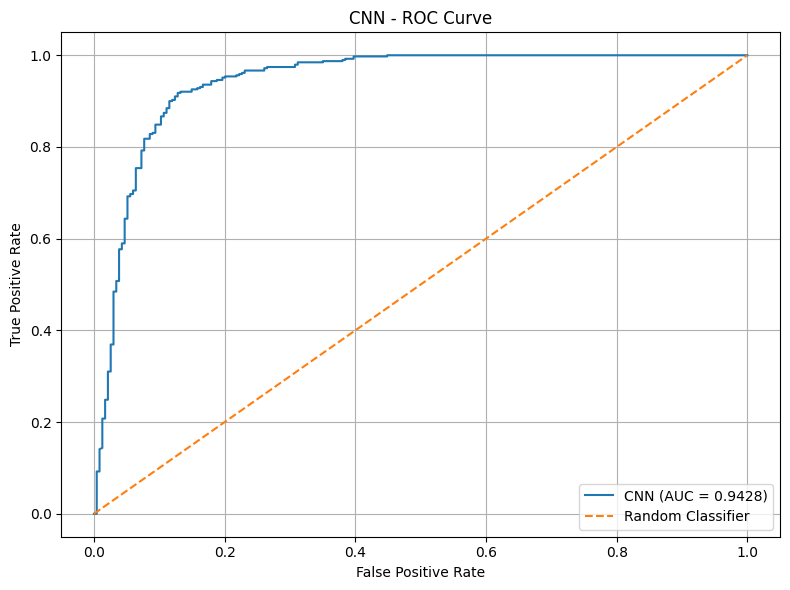

In [22]:
# ================================================================
# CNN ROC CURVE
# ================================================================

import matplotlib.pyplot as plt
from sklearn.metrics import roc_curve, roc_auc_score

print("=" * 70)
print("CNN ROC CURVE")
print("=" * 70)

# Calculate ROC values
fpr, tpr, thresholds = roc_curve(y_test, y_test_prob)

# Calculate AUC
roc_auc = roc_auc_score(y_test, y_test_prob)

print(f"\nROC-AUC: {roc_auc:.4f}")

# Plot ROC curve
plt.figure(figsize=(8, 6))

plt.plot(
    fpr,
    tpr,
    label=f"CNN (AUC = {roc_auc:.4f})"
)

# Random classifier reference
plt.plot(
    [0, 1],
    [0, 1],
    linestyle="--",
    label="Random Classifier"
)

plt.xlabel("False Positive Rate")
plt.ylabel("True Positive Rate")
plt.title("CNN - ROC Curve")
plt.legend(loc="lower right")
plt.grid(True)

plt.tight_layout()
plt.show()

In [23]:
# ================================================================
# CNN THRESHOLD ANALYSIS
# ================================================================

import numpy as np
import pandas as pd
from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score
)

print("=" * 70)
print("CNN THRESHOLD ANALYSIS")
print("=" * 70)

thresholds = np.arange(0.10, 0.91, 0.05)

results = []

for threshold in thresholds:

    predictions = (y_test_prob >= threshold).astype(int)

    results.append({
        "Threshold": round(threshold, 2),
        "Accuracy": accuracy_score(y_test, predictions),
        "Precision": precision_score(
            y_test, predictions, zero_division=0
        ),
        "Recall": recall_score(
            y_test, predictions, zero_division=0
        ),
        "F1 Score": f1_score(
            y_test, predictions, zero_division=0
        )
    })

threshold_results = pd.DataFrame(results)

print("\nThreshold Performance:")
print(
    threshold_results.to_string(
        index=False,
        formatters={
            "Accuracy": "{:.4f}".format,
            "Precision": "{:.4f}".format,
            "Recall": "{:.4f}".format,
            "F1 Score": "{:.4f}".format
        }
    )
)

CNN THRESHOLD ANALYSIS

Threshold Performance:
 Threshold Accuracy Precision Recall F1 Score
      0.10   0.8365    0.7939 0.9974   0.8841
      0.15   0.8462    0.8063 0.9923   0.8897
      0.20   0.8542    0.8174 0.9872   0.8943
      0.25   0.8574    0.8209 0.9872   0.8964
      0.30   0.8606    0.8258 0.9846   0.8982
      0.35   0.8622    0.8276 0.9846   0.8993
      0.40   0.8718    0.8384 0.9846   0.9057
      0.45   0.8718    0.8399 0.9821   0.9054
      0.50   0.8718    0.8444 0.9744   0.9048
      0.55   0.8750    0.8482 0.9744   0.9069
      0.60   0.8798    0.8539 0.9744   0.9102
      0.65   0.8846    0.8597 0.9744   0.9135
      0.70   0.8814    0.8607 0.9667   0.9106
      0.75   0.8926    0.8747 0.9667   0.9184
      0.80   0.8894    0.8759 0.9590   0.9155
      0.85   0.8942    0.8857 0.9538   0.9185
      0.90   0.8958    0.8935 0.9462   0.9191


In [24]:
# ================================================================
# CNN VALIDATION THRESHOLD ANALYSIS
# ================================================================

import numpy as np
import pandas as pd

from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score
)

print("=" * 70)
print("CNN VALIDATION THRESHOLD ANALYSIS")
print("=" * 70)

# Load best CNN model
best_cnn_model = keras.models.load_model(
    "../models/image_pneumonia_cnn_best.keras"
)

# Validation probabilities
y_val_prob = best_cnn_model.predict(
    X_val_processed,
    verbose=0
).ravel()

thresholds = np.arange(0.10, 0.91, 0.05)

results = []

for threshold in thresholds:

    y_val_pred = (
        y_val_prob >= threshold
    ).astype(int)

    results.append({
        "Threshold": round(threshold, 2),
        "Accuracy": accuracy_score(
            y_val, y_val_pred
        ),
        "Precision": precision_score(
            y_val, y_val_pred,
            zero_division=0
        ),
        "Recall": recall_score(
            y_val, y_val_pred,
            zero_division=0
        ),
        "F1 Score": f1_score(
            y_val, y_val_pred,
            zero_division=0
        )
    })

val_threshold_results = pd.DataFrame(results)

print("\nValidation Threshold Performance:")

print(
    val_threshold_results.to_string(
        index=False,
        formatters={
            "Accuracy": "{:.4f}".format,
            "Precision": "{:.4f}".format,
            "Recall": "{:.4f}".format,
            "F1 Score": "{:.4f}".format
        }
    )
)

CNN VALIDATION THRESHOLD ANALYSIS

Validation Threshold Performance:
 Threshold Accuracy Precision Recall F1 Score
      0.10   0.9676    0.9650 0.9923   0.9785
      0.15   0.9656    0.9649 0.9897   0.9772
      0.20   0.9714    0.9746 0.9871   0.9808
      0.25   0.9733    0.9795 0.9846   0.9821
      0.30   0.9733    0.9820 0.9820   0.9820
      0.35   0.9733    0.9845 0.9794   0.9820
      0.40   0.9714    0.9870 0.9743   0.9806
      0.45   0.9714    0.9870 0.9743   0.9806
      0.50   0.9695    0.9869 0.9717   0.9793
      0.55   0.9695    0.9869 0.9717   0.9793
      0.60   0.9676    0.9869 0.9692   0.9780
      0.65   0.9676    0.9869 0.9692   0.9780
      0.70   0.9656    0.9894 0.9640   0.9766
      0.75   0.9637    0.9920 0.9589   0.9752
      0.80   0.9561    0.9919 0.9486   0.9698
      0.85   0.9523    0.9919 0.9434   0.9671
      0.90   0.9466    0.9972 0.9306   0.9628


In [25]:
# ================================================================
# FINAL CNN TEST EVALUATION
# Locked threshold = 0.55
# ================================================================

import numpy as np
import pandas as pd
import tensorflow as tf

from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    roc_auc_score,
    confusion_matrix,
    classification_report
)

print("=" * 70)
print("FINAL CNN TEST EVALUATION")
print("=" * 70)

# ------------------------------------------------
# 1. Load best model
# ------------------------------------------------

best_cnn_model = tf.keras.models.load_model(
    "../models/image_pneumonia_cnn_best.keras"
)

# ------------------------------------------------
# 2. Final locked threshold
# ------------------------------------------------

FINAL_THRESHOLD = 0.55

print(f"\nFinal decision threshold: {FINAL_THRESHOLD}")

# ------------------------------------------------
# 3. Generate test probabilities
# ------------------------------------------------

y_test_prob = best_cnn_model.predict(
    X_test_processed,
    verbose=0
).ravel()

# ------------------------------------------------
# 4. Convert probabilities to predictions
# ------------------------------------------------

y_test_pred = (
    y_test_prob >= FINAL_THRESHOLD
).astype(int)

# ------------------------------------------------
# 5. Calculate final metrics
# ------------------------------------------------

test_accuracy = accuracy_score(
    y_test,
    y_test_pred
)

test_precision = precision_score(
    y_test,
    y_test_pred,
    zero_division=0
)

test_recall = recall_score(
    y_test,
    y_test_pred,
    zero_division=0
)

test_f1 = f1_score(
    y_test,
    y_test_pred,
    zero_division=0
)

test_auc = roc_auc_score(
    y_test,
    y_test_prob
)

# ------------------------------------------------
# 6. Display metrics
# ------------------------------------------------

print("\n" + "=" * 70)
print("FINAL TEST PERFORMANCE")
print("=" * 70)

print(f"Accuracy  : {test_accuracy:.4f}")
print(f"Precision : {test_precision:.4f}")
print(f"Recall    : {test_recall:.4f}")
print(f"F1 Score  : {test_f1:.4f}")
print(f"AUC       : {test_auc:.4f}")

# ------------------------------------------------
# 7. Confusion Matrix
# ------------------------------------------------

cm = confusion_matrix(
    y_test,
    y_test_pred
)

print("\nConfusion Matrix:")
print(cm)

# ------------------------------------------------
# 8. Classification Report
# ------------------------------------------------

print("\nClassification Report:")

print(
    classification_report(
        y_test,
        y_test_pred,
        target_names=["Normal", "Pneumonia"],
        digits=4
    )
)

FINAL CNN TEST EVALUATION

Final decision threshold: 0.55

FINAL TEST PERFORMANCE
Accuracy  : 0.8750
Precision : 0.8482
Recall    : 0.9744
F1 Score  : 0.9069
AUC       : 0.9428

Confusion Matrix:
[[166  68]
 [ 10 380]]

Classification Report:
              precision    recall  f1-score   support

      Normal     0.9432    0.7094    0.8098       234
   Pneumonia     0.8482    0.9744    0.9069       390

    accuracy                         0.8750       624
   macro avg     0.8957    0.8419    0.8583       624
weighted avg     0.8838    0.8750    0.8705       624



CNN SAMPLE PREDICTIONS

Prediction Results:
----------------------------------------------------------------------
 1. Actual: Normal     | Predicted: Pneumonia  | Confidence: 66.29% | INCORRECT
 2. Actual: Normal     | Predicted: Normal     | Confidence: 99.63% | CORRECT
 3. Actual: Pneumonia  | Predicted: Pneumonia  | Confidence: 100.00% | CORRECT
 4. Actual: Pneumonia  | Predicted: Pneumonia  | Confidence: 99.99% | CORRECT
 5. Actual: Pneumonia  | Predicted: Pneumonia  | Confidence: 99.99% | CORRECT
 6. Actual: Normal     | Predicted: Normal     | Confidence: 89.61% | CORRECT
 7. Actual: Pneumonia  | Predicted: Pneumonia  | Confidence: 100.00% | CORRECT
 8. Actual: Normal     | Predicted: Normal     | Confidence: 94.13% | CORRECT
 9. Actual: Pneumonia  | Predicted: Pneumonia  | Confidence: 100.00% | CORRECT
10. Actual: Normal     | Predicted: Normal     | Confidence: 99.80% | CORRECT


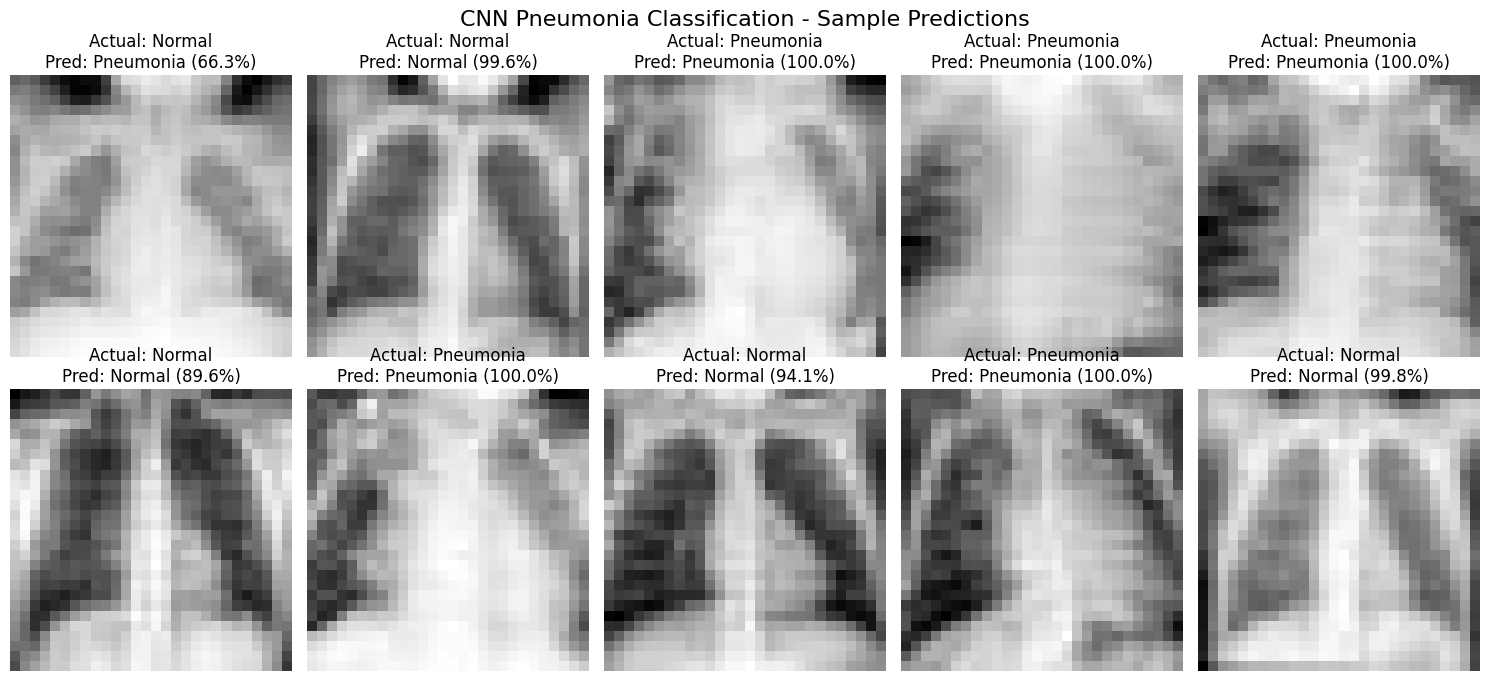

In [26]:
# ================================================================
# CNN SAMPLE PREDICTIONS
# ================================================================

import numpy as np
import matplotlib.pyplot as plt

print("=" * 70)
print("CNN SAMPLE PREDICTIONS")
print("=" * 70)

# Select a few test images
num_samples = 10

np.random.seed(42)
sample_indices = np.random.choice(
    len(X_test_processed),
    num_samples,
    replace=False
)

# Get probabilities
sample_images = X_test_processed[sample_indices]
sample_actual = y_test[sample_indices]

sample_probabilities = best_cnn_model.predict(
    sample_images,
    verbose=0
).ravel()

# Apply locked threshold
sample_predictions = (
    sample_probabilities >= FINAL_THRESHOLD
).astype(int)

class_names = {
    0: "Normal",
    1: "Pneumonia"
}

# Print results
print("\nPrediction Results:")
print("-" * 70)

for i in range(num_samples):

    actual = class_names[int(sample_actual[i])]
    predicted = class_names[int(sample_predictions[i])]
    probability = sample_probabilities[i]

    if predicted == "Pneumonia":
        confidence = probability
    else:
        confidence = 1 - probability

    status = "CORRECT" if actual == predicted else "INCORRECT"

    print(
        f"{i+1:2d}. "
        f"Actual: {actual:10s} | "
        f"Predicted: {predicted:10s} | "
        f"Confidence: {confidence:.2%} | "
        f"{status}"
    )

# ------------------------------------------------
# Display images
# ------------------------------------------------

fig, axes = plt.subplots(
    2, 5,
    figsize=(15, 7)
)

axes = axes.ravel()

for i, ax in enumerate(axes):

    ax.imshow(
        sample_images[i].squeeze(),
        cmap="gray"
    )

    actual = class_names[int(sample_actual[i])]
    predicted = class_names[int(sample_predictions[i])]
    probability = sample_probabilities[i]

    if predicted == "Pneumonia":
        confidence = probability
    else:
        confidence = 1 - probability

    ax.set_title(
        f"Actual: {actual}\n"
        f"Pred: {predicted} ({confidence:.1%})"
    )

    ax.axis("off")

plt.suptitle(
    "CNN Pneumonia Classification - Sample Predictions",
    fontsize=16
)

plt.tight_layout()
plt.show()

In [27]:
# ================================================================
# GRAD-CAM - CNN EXPLAINABILITY
# ================================================================

import tensorflow as tf
import numpy as np
import matplotlib.pyplot as plt

print("=" * 70)
print("CNN GRAD-CAM EXPLAINABILITY")
print("=" * 70)

# ------------------------------------------------
# Identify final convolutional layer
# ------------------------------------------------

last_conv_layer_name = "conv2d_2"

last_conv_layer = best_cnn_model.get_layer(
    last_conv_layer_name
)

print(f"\nLast convolutional layer: {last_conv_layer_name}")
print(f"Layer output shape: {last_conv_layer.output.shape}")


# ------------------------------------------------
# Grad-CAM function
# ------------------------------------------------

def make_gradcam_heatmap(
    image,
    model,
    last_conv_layer_name
):
    """
    Generate a Grad-CAM heatmap for a single image.

    Class 0 = Normal
    Class 1 = Pneumonia
    """

    # Add batch dimension
    img_array = np.expand_dims(image, axis=0).astype(np.float32)

    # Get convolutional layer
    conv_layer = model.get_layer(last_conv_layer_name)

    # Create model that returns:
    # 1. convolutional feature maps
    # 2. final prediction
    grad_model = tf.keras.models.Model(
        inputs=model.inputs,
        outputs=[
            conv_layer.output,
            model.output
        ]
    )

    # Calculate gradients
    with tf.GradientTape() as tape:

        conv_outputs, predictions = grad_model(img_array)

        pneumonia_probability = predictions[:, 0]

        # Determine predicted class
        predicted_class = int(
            pneumonia_probability.numpy()[0] >= FINAL_THRESHOLD
        )

        # Explain the predicted class
        if predicted_class == 1:
            target_score = pneumonia_probability
        else:
            target_score = 1.0 - pneumonia_probability

    # Gradient of target class
    grads = tape.gradient(
        target_score,
        conv_outputs
    )

    # Average gradients across spatial dimensions
    pooled_grads = tf.reduce_mean(
        grads,
        axis=(1, 2)
    )

    # Remove batch dimension
    conv_outputs = conv_outputs[0]
    pooled_grads = pooled_grads[0]

    # Weight feature maps by importance
    heatmap = tf.reduce_sum(
        conv_outputs * pooled_grads,
        axis=-1
    )

    # Apply ReLU
    heatmap = tf.maximum(
        heatmap,
        0
    )

    # Normalize between 0 and 1
    max_value = tf.reduce_max(heatmap)

    if max_value > 0:
        heatmap /= max_value

    return heatmap.numpy(), predicted_class


print("\nGrad-CAM function created successfully.")

CNN GRAD-CAM EXPLAINABILITY

Last convolutional layer: conv2d_2
Layer output shape: (None, 7, 7, 128)

Grad-CAM function created successfully.


In [28]:
# ================================================================
# GRAD-CAM FUNCTION - KERAS 3 / SEQUENTIAL COMPATIBLE
# ================================================================

import tensorflow as tf
import numpy as np
import matplotlib.pyplot as plt

print("=" * 70)
print("GRAD-CAM FUNCTION")
print("=" * 70)


# ------------------------------------------------
# Identify final convolutional layer
# ------------------------------------------------

last_conv_layer_name = "conv2d_2"

last_conv_layer = best_cnn_model.get_layer(
    last_conv_layer_name
)

# Find layer position
conv_layer_index = best_cnn_model.layers.index(
    last_conv_layer
)

print(f"\nLast convolutional layer : {last_conv_layer_name}")
print(f"Layer index               : {conv_layer_index}")
print(f"Layer output shape        : {last_conv_layer.output.shape}")


# ------------------------------------------------
# Create feature extractor
# ------------------------------------------------

feature_extractor = tf.keras.Model(
    inputs=best_cnn_model.inputs,
    outputs=last_conv_layer.output
)


# ------------------------------------------------
# Create classifier from layers AFTER conv2d_2
# ------------------------------------------------

classifier_layers = best_cnn_model.layers[
    conv_layer_index + 1:
]

classifier = tf.keras.Sequential(
    classifier_layers
)


print(
    f"Classifier layers after convolutional layer: "
    f"{len(classifier_layers)}"
)


# ------------------------------------------------
# Grad-CAM function
# ------------------------------------------------

def make_gradcam_heatmap(
    image,
    feature_extractor,
    classifier
):
    """
    Generate a Grad-CAM heatmap.

    Class 0 = Normal
    Class 1 = Pneumonia
    """

    # ------------------------------------------------
    # Prepare image
    # ------------------------------------------------

    img_array = np.expand_dims(
        image,
        axis=0
    ).astype(np.float32)


    # ------------------------------------------------
    # Gradient calculation
    # ------------------------------------------------

    with tf.GradientTape() as tape:

        # Extract convolutional feature maps
        conv_outputs = feature_extractor(
            img_array,
            training=False
        )

        # Watch convolutional feature maps
        tape.watch(conv_outputs)

        # Pass feature maps through remaining CNN
        predictions = classifier(
            conv_outputs,
            training=False
        )

        # Pneumonia probability
        pneumonia_probability = predictions[:, 0]

        # Determine predicted class
        predicted_class = int(
            pneumonia_probability.numpy()[0]
            >= FINAL_THRESHOLD
        )

        # Explain predicted class
        if predicted_class == 1:
            target_score = pneumonia_probability
        else:
            target_score = 1.0 - pneumonia_probability


    # ------------------------------------------------
    # Calculate gradients
    # ------------------------------------------------

    grads = tape.gradient(
        target_score,
        conv_outputs
    )


    # ------------------------------------------------
    # Global average pooling
    # ------------------------------------------------

    pooled_grads = tf.reduce_mean(
        grads,
        axis=(1, 2)
    )


    # Remove batch dimension
    conv_outputs = conv_outputs[0]
    pooled_grads = pooled_grads[0]


    # ------------------------------------------------
    # Weight feature maps
    # ------------------------------------------------

    heatmap = tf.reduce_sum(
        conv_outputs * pooled_grads,
        axis=-1
    )


    # ------------------------------------------------
    # ReLU
    # ------------------------------------------------

    heatmap = tf.maximum(
        heatmap,
        0
    )


    # ------------------------------------------------
    # Normalize
    # ------------------------------------------------

    max_value = tf.reduce_max(
        heatmap
    )

    if float(max_value) > 0:
        heatmap = heatmap / max_value


    return heatmap.numpy(), predicted_class


print("\nGrad-CAM function created successfully.")
print("Keras 3 compatible implementation.")

GRAD-CAM FUNCTION

Last convolutional layer : conv2d_2
Layer index               : 4
Layer output shape        : (None, 7, 7, 128)
Classifier layers after convolutional layer: 5

Grad-CAM function created successfully.
Keras 3 compatible implementation.


GRAD-CAM SAMPLE VISUALIZATION


c:\Users\aquil\AI-Medical-Diagnosis-Platform\aipp\lib\site-packages\keras\src\models\functional.py:241: UserWarning: The structure of `inputs` doesn't match the expected structure.
Expected: ['input_layer']
Received: inputs=Tensor(shape=(1, 28, 28, 1))
  warnings.warn(msg)


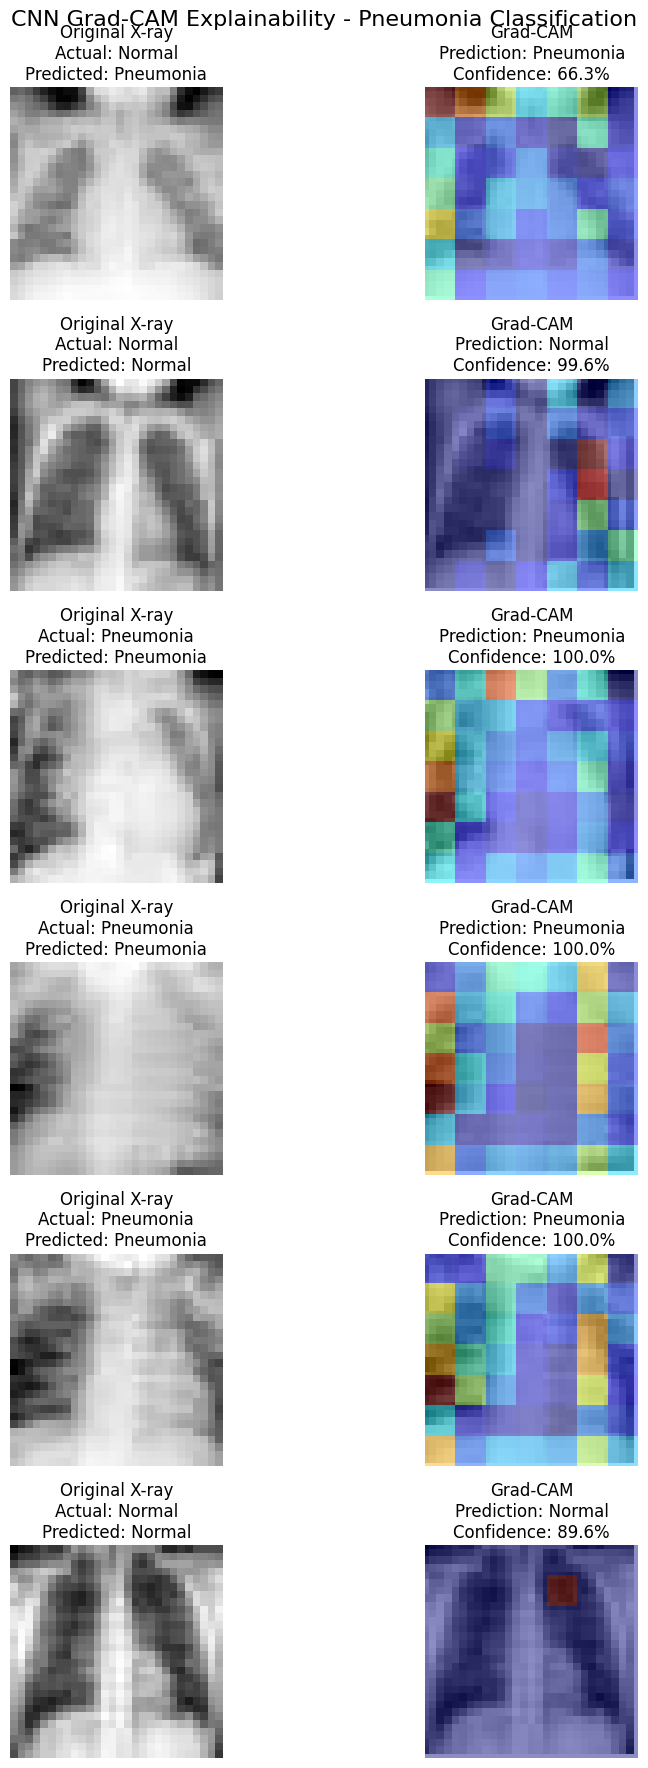

In [29]:
# ================================================================
# GRAD-CAM SAMPLE VISUALIZATION
# ================================================================

print("=" * 70)
print("GRAD-CAM SAMPLE VISUALIZATION")
print("=" * 70)


# ------------------------------------------------
# Samples to visualize
# ------------------------------------------------

num_gradcam_samples = 6


# ------------------------------------------------
# Create figure
# ------------------------------------------------

fig, axes = plt.subplots(
    num_gradcam_samples,
    2,
    figsize=(10, 18)
)


class_names = {
    0: "Normal",
    1: "Pneumonia"
}


# ------------------------------------------------
# Generate Grad-CAM
# ------------------------------------------------

for row, i in enumerate(
    range(num_gradcam_samples)
):

    image = sample_images[i]

    actual_class = int(
        sample_actual[i]
    )

    probability = float(
        sample_probabilities[i]
    )

    predicted_class = int(
        probability >= FINAL_THRESHOLD
    )


    # Generate heatmap
    heatmap, _ = make_gradcam_heatmap(
        image,
        feature_extractor,
        classifier
    )


    # Confidence
    confidence = (
        probability
        if predicted_class == 1
        else 1 - probability
    )


    # ------------------------------------------------
    # Original X-ray
    # ------------------------------------------------

    axes[row, 0].imshow(
        image.squeeze(),
        cmap="gray"
    )

    axes[row, 0].set_title(
        f"Original X-ray\n"
        f"Actual: {class_names[actual_class]}\n"
        f"Predicted: {class_names[predicted_class]}"
    )

    axes[row, 0].axis("off")


    # ------------------------------------------------
    # Grad-CAM
    # ------------------------------------------------

    axes[row, 1].imshow(
        image.squeeze(),
        cmap="gray"
    )

    axes[row, 1].imshow(
        heatmap,
        cmap="jet",
        alpha=0.45,
        extent=(
            0,
            image.shape[1],
            image.shape[0],
            0
        )
    )

    axes[row, 1].set_title(
        f"Grad-CAM\n"
        f"Prediction: {class_names[predicted_class]}\n"
        f"Confidence: {confidence:.1%}"
    )

    axes[row, 1].axis("off")


# ------------------------------------------------
# Final layout
# ------------------------------------------------

plt.suptitle(
    "CNN Grad-CAM Explainability - Pneumonia Classification",
    fontsize=16
)

plt.tight_layout()
plt.show()

# Experiment 2 — Image Processing Enhancement

The baseline CNN model was developed using normalized PneumoniaMNIST images. In this experiment, image-processing techniques are applied to enhance image quality and contrast before CNN training. The resulting model will be compared with the baseline CNN to determine whether image enhancement improves classification performance.

In [30]:
# ================================================================
# IMAGE PROCESSING - ENHANCEMENT TECHNIQUES
# ================================================================

import numpy as np
import matplotlib.pyplot as plt

from scipy.ndimage import gaussian_filter
from skimage import exposure

print("=" * 70)
print("IMAGE PROCESSING - ENHANCEMENT TECHNIQUES")
print("=" * 70)

print("\nOriginal dataset shapes:")
print(f"Training   : {X_train.shape}")
print(f"Validation : {X_val.shape}")
print(f"Testing    : {X_test.shape}")

print("\nImage processing techniques to be evaluated:")
print("1. Contrast Enhancement")
print("2. CLAHE (Adaptive Histogram Equalization)")
print("3. Mild Gaussian Denoising")
print("4. Final Enhanced Image")

print("\nExperiment 1 data will remain unchanged.")
print("New enhanced datasets will be created separately.")

IMAGE PROCESSING - ENHANCEMENT TECHNIQUES

Original dataset shapes:
Training   : (4708, 28, 28)
Validation : (524, 28, 28)
Testing    : (624, 28, 28)

Image processing techniques to be evaluated:
1. Contrast Enhancement
2. CLAHE (Adaptive Histogram Equalization)
3. Mild Gaussian Denoising
4. Final Enhanced Image

Experiment 1 data will remain unchanged.
New enhanced datasets will be created separately.


In [31]:
# ================================================================
# IMAGE ENHANCEMENT FUNCTIONS
# ================================================================

def enhance_image(image):
    """
    Apply mild image-processing enhancement to a single
    grayscale X-ray image.

    Steps:
    1. Contrast enhancement
    2. CLAHE
    3. Mild Gaussian denoising
    4. Final normalization
    """

    # Ensure image is in the range 0-1
    image = np.asarray(image, dtype=np.float32)

    if image.max() > 1.0:
        image = image / 255.0

    # ------------------------------------------------------------
    # Step 1: Contrast enhancement
    # ------------------------------------------------------------
    contrast_image = exposure.rescale_intensity(
        image,
        in_range="image",
        out_range=(0.0, 1.0)
    )

    # ------------------------------------------------------------
    # Step 2: CLAHE
    # ------------------------------------------------------------
    clahe_image = exposure.equalize_adapthist(
        contrast_image,
        clip_limit=0.02
    )

    # ------------------------------------------------------------
    # Step 3: Mild Gaussian denoising
    # ------------------------------------------------------------
    denoised_image = gaussian_filter(
        clahe_image,
        sigma=0.5
    )

    # ------------------------------------------------------------
    # Step 4: Final normalization
    # ------------------------------------------------------------
    enhanced_image = np.clip(
        denoised_image,
        0.0,
        1.0
    )

    return enhanced_image


print("=" * 70)
print("IMAGE ENHANCEMENT FUNCTIONS")
print("=" * 70)

print("\nEnhancement function created successfully.")
print("Techniques:")
print("  - Contrast enhancement")
print("  - CLAHE")
print("  - Mild Gaussian denoising")
print("  - Final normalization")

IMAGE ENHANCEMENT FUNCTIONS

Enhancement function created successfully.
Techniques:
  - Contrast enhancement
  - CLAHE
  - Mild Gaussian denoising
  - Final normalization


ORIGINAL VS ENHANCED IMAGE COMPARISON


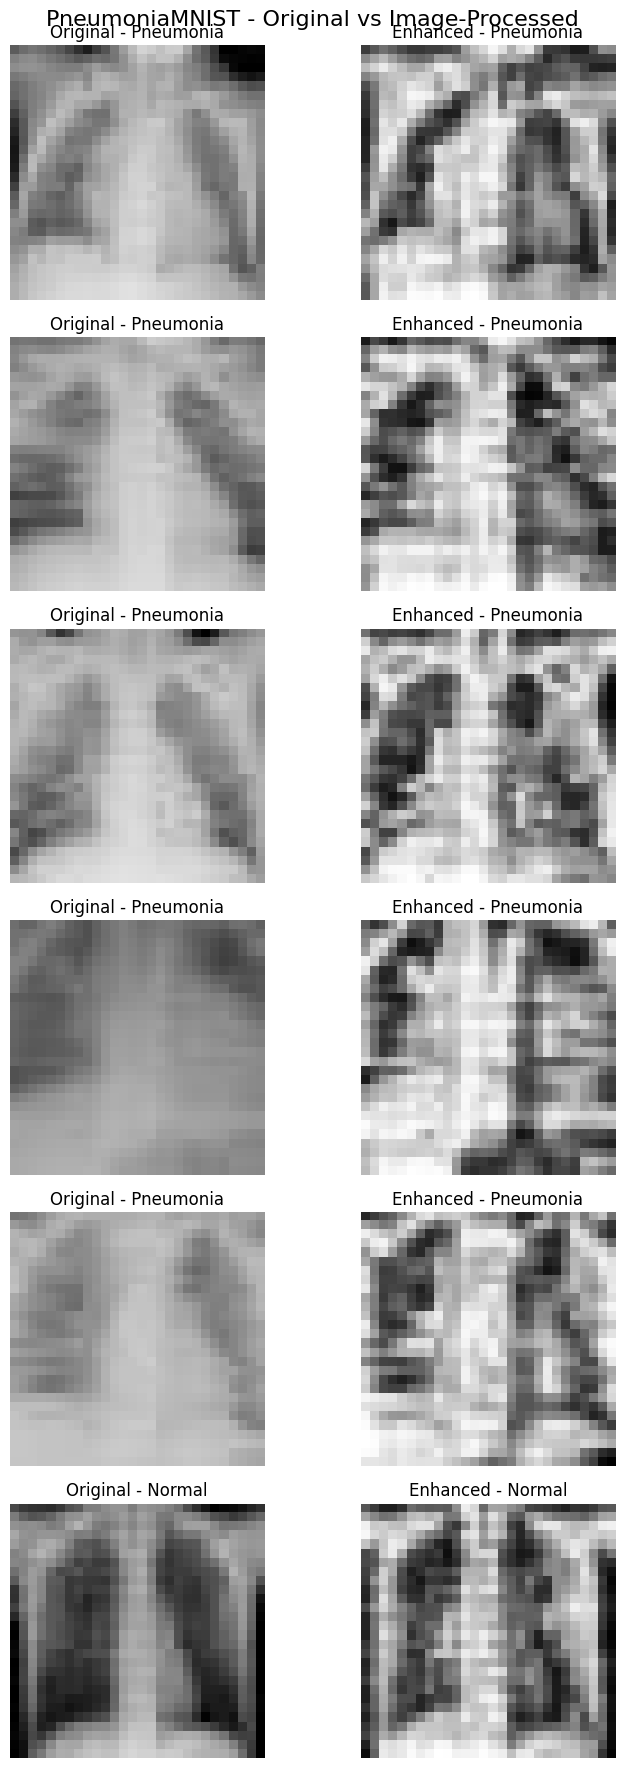

In [32]:
# ================================================================
# COMPARE ORIGINAL AND ENHANCED IMAGES
# ================================================================

print("=" * 70)
print("ORIGINAL VS ENHANCED IMAGE COMPARISON")
print("=" * 70)

# Select representative images
sample_indices = [0, 1, 2, 3, 4, 5]

fig, axes = plt.subplots(
    len(sample_indices),
    2,
    figsize=(8, 18)
)

class_names = {
    0: "Normal",
    1: "Pneumonia"
}

for row, idx in enumerate(sample_indices):

    # Original image: uint8, range 0-255
    original = X_train[idx]

    # Enhanced image: normalized, range 0-1
    enhanced = enhance_image(original)

    # ------------------------------------------------------------
    # Original
    # ------------------------------------------------------------
    axes[row, 0].imshow(
        original,
        cmap="gray",
        vmin=0,
        vmax=255
    )

    axes[row, 0].set_title(
        f"Original - {class_names[int(y_train[idx])]}"
    )

    axes[row, 0].axis("off")

    # ------------------------------------------------------------
    # Enhanced
    # ------------------------------------------------------------
    axes[row, 1].imshow(
        enhanced,
        cmap="gray",
        vmin=0,
        vmax=1
    )

    axes[row, 1].set_title(
        f"Enhanced - {class_names[int(y_train[idx])]}"
    )

    axes[row, 1].axis("off")


plt.suptitle(
    "PneumoniaMNIST - Original vs Image-Processed",
    fontsize=16
)

plt.tight_layout()
plt.show()

In [33]:
# ================================================================
# CREATE ENHANCED DATASETS
# ================================================================

print("=" * 70)
print("CREATING ENHANCED DATASETS")
print("=" * 70)

start_time = time.time()

# ------------------------------------------------
# Apply enhancement to all datasets
# ------------------------------------------------

X_train_enhanced = np.array([
    enhance_image(image)
    for image in X_train
], dtype=np.float32)

X_val_enhanced = np.array([
    enhance_image(image)
    for image in X_val
], dtype=np.float32)

X_test_enhanced = np.array([
    enhance_image(image)
    for image in X_test
], dtype=np.float32)

# ------------------------------------------------
# Add channel dimension
# ------------------------------------------------

X_train_enhanced = X_train_enhanced[..., np.newaxis]
X_val_enhanced = X_val_enhanced[..., np.newaxis]
X_test_enhanced = X_test_enhanced[..., np.newaxis]

processing_time = time.time() - start_time

print("\nEnhanced datasets created successfully.")

print("\nEnhanced dataset shapes:")
print(f"Training   : {X_train_enhanced.shape}")
print(f"Validation : {X_val_enhanced.shape}")
print(f"Testing    : {X_test_enhanced.shape}")

print("\nEnhanced data types:")
print(f"Training   : {X_train_enhanced.dtype}")
print(f"Validation : {X_val_enhanced.dtype}")
print(f"Testing    : {X_test_enhanced.dtype}")

print("\nEnhanced pixel ranges:")
print(
    f"Training   : min={X_train_enhanced.min():.4f}, "
    f"max={X_train_enhanced.max():.4f}"
)

print(
    f"Validation : min={X_val_enhanced.min():.4f}, "
    f"max={X_val_enhanced.max():.4f}"
)

print(
    f"Testing    : min={X_test_enhanced.min():.4f}, "
    f"max={X_test_enhanced.max():.4f}"
)

print(f"\nProcessing time: {processing_time:.2f} seconds")

CREATING ENHANCED DATASETS

Enhanced datasets created successfully.

Enhanced dataset shapes:
Training   : (4708, 28, 28, 1)
Validation : (524, 28, 28, 1)
Testing    : (624, 28, 28, 1)

Enhanced data types:
Training   : float32
Validation : float32
Testing    : float32

Enhanced pixel ranges:
Training   : min=0.0010, max=1.0000
Validation : min=0.0010, max=1.0000
Testing    : min=0.0010, max=1.0000

Processing time: 22.45 seconds


In [34]:
# ================================================================
# ENHANCED DATASET STATISTICS
# ================================================================

print("=" * 70)
print("ENHANCED DATASET STATISTICS")
print("=" * 70)

print("\nPixel statistics - Enhanced Training Set:")

print(f"Mean       : {X_train_enhanced.mean():.4f}")
print(f"Std        : {X_train_enhanced.std():.4f}")
print(f"Median     : {np.median(X_train_enhanced):.4f}")
print(f"Min        : {X_train_enhanced.min():.4f}")
print(f"Max        : {X_train_enhanced.max():.4f}")

print("\nDataset memory usage:")

print(
    f"Training   : "
    f"{X_train_enhanced.nbytes / (1024 ** 2):.2f} MB"
)

print(
    f"Validation : "
    f"{X_val_enhanced.nbytes / (1024 ** 2):.2f} MB"
)

print(
    f"Testing    : "
    f"{X_test_enhanced.nbytes / (1024 ** 2):.2f} MB"
)

print("\nClass labels remain unchanged:")

print(f"Training labels   : {y_train.shape}")
print(f"Validation labels : {y_val.shape}")
print(f"Testing labels    : {y_test.shape}")

print("\nExperiment 2 preprocessing completed successfully.")

ENHANCED DATASET STATISTICS

Pixel statistics - Enhanced Training Set:
Mean       : 0.5957
Std        : 0.2404
Median     : 0.6241
Min        : 0.0010
Max        : 1.0000

Dataset memory usage:
Training   : 14.08 MB
Validation : 1.57 MB
Testing    : 1.87 MB

Class labels remain unchanged:
Training labels   : (4708,)
Validation labels : (524,)
Testing labels    : (624,)

Experiment 2 preprocessing completed successfully.


In [35]:
# ================================================================
# EXPERIMENT 2 — CNN MODEL ARCHITECTURE
# ================================================================

import tensorflow as tf
from tensorflow import keras
from tensorflow.keras import layers

print("=" * 70)
print("EXPERIMENT 2 - CNN MODEL ARCHITECTURE")
print("=" * 70)

# Create CNN model for enhanced images
cnn_model_enhanced = keras.Sequential([
    
    # Input
    layers.Input(shape=(28, 28, 1)),

    # Convolution Block 1
    layers.Conv2D(
        32,
        kernel_size=(3, 3),
        activation="relu",
        padding="same"
    ),
    layers.MaxPooling2D(pool_size=(2, 2)),

    # Convolution Block 2
    layers.Conv2D(
        64,
        kernel_size=(3, 3),
        activation="relu",
        padding="same"
    ),
    layers.MaxPooling2D(pool_size=(2, 2)),

    # Convolution Block 3
    layers.Conv2D(
        128,
        kernel_size=(3, 3),
        activation="relu",
        padding="same"
    ),
    layers.MaxPooling2D(pool_size=(2, 2)),

    # Flatten
    layers.Flatten(),

    # Fully Connected Layer
    layers.Dense(128, activation="relu"),

    # Dropout
    layers.Dropout(0.5),

    # Output Layer
    layers.Dense(1, activation="sigmoid")
])

# Display architecture
cnn_model_enhanced.summary()

EXPERIMENT 2 - CNN MODEL ARCHITECTURE


Model: "sequential_2"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ conv2d_3 (Conv2D)               │ (None, 28, 28, 32)     │           320 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_3 (MaxPooling2D)  │ (None, 14, 14, 32)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_4 (Conv2D)               │ (None, 14, 14, 64)     │        18,496 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_4 (MaxPooling2D)  │ (None, 7, 7, 64)       │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_5 (Conv2D)               │ (None, 7, 7, 128)      │        73,856 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_5 (MaxPooling2D)  │ (None, 3, 3, 128)      │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ flatten_1 (Flatten)             │ (None, 1152)           │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_2 (Dense)                 │ (None, 128)            │       147,584 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_1 (Dropout)             │ (None, 128)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_3 (Dense)                 │ (None, 1)              │           129 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 240,385 (939.00 KB)

 Trainable params: 240,385 (939.00 KB)

 Non-trainable params: 0 (0.00 B)

In [36]:
# ================================================================
# EXPERIMENT 2 — CNN MODEL COMPILATION
# ================================================================

print("=" * 70)
print("EXPERIMENT 2 - CNN MODEL COMPILATION")
print("=" * 70)

# Compile CNN model
cnn_model_enhanced.compile(
    optimizer=keras.optimizers.Adam(learning_rate=0.001),
    loss="binary_crossentropy",
    metrics=[
        "accuracy",
        keras.metrics.Precision(name="precision"),
        keras.metrics.Recall(name="recall"),
        keras.metrics.AUC(name="auc")
    ]
)

print("\nCNN enhanced model compiled successfully.")
print("Loss function    : Binary Cross-Entropy")
print("Optimizer        : Adam")
print("Learning rate    : 0.001")
print("Metrics          : Accuracy, Precision, Recall, AUC")

EXPERIMENT 2 - CNN MODEL COMPILATION

CNN enhanced model compiled successfully.
Loss function    : Binary Cross-Entropy
Optimizer        : Adam
Learning rate    : 0.001
Metrics          : Accuracy, Precision, Recall, AUC


In [37]:
# ================================================================
# EXPERIMENT 2 — CNN TRAINING CALLBACKS
# ================================================================

import os

print("=" * 70)
print("EXPERIMENT 2 - CNN TRAINING CALLBACKS")
print("=" * 70)

# Create model directory if it does not exist
os.makedirs("../models", exist_ok=True)

# Best model path
enhanced_model_path = "../models/image_pneumonia_cnn_enhanced_best.keras"

# Early stopping
early_stopping_enhanced = keras.callbacks.EarlyStopping(
    monitor="val_loss",
    patience=5,
    restore_best_weights=True,
    verbose=1
)

# Reduce learning rate when validation loss stops improving
reduce_lr_enhanced = keras.callbacks.ReduceLROnPlateau(
    monitor="val_loss",
    factor=0.5,
    patience=2,
    min_lr=1e-6,
    verbose=1
)

# Save the best model
model_checkpoint_enhanced = keras.callbacks.ModelCheckpoint(
    enhanced_model_path,
    monitor="val_loss",
    save_best_only=True,
    verbose=1
)

# Combine callbacks
callbacks_enhanced = [
    early_stopping_enhanced,
    reduce_lr_enhanced,
    model_checkpoint_enhanced
]

print("\nCallbacks configured successfully.")
print("Early stopping patience : 5 epochs")
print("LR reduction factor     : 0.5")
print(f"Best model path         : {enhanced_model_path}")

EXPERIMENT 2 - CNN TRAINING CALLBACKS

Callbacks configured successfully.
Early stopping patience : 5 epochs
LR reduction factor     : 0.5
Best model path         : ../models/image_pneumonia_cnn_enhanced_best.keras


In [38]:
# ================================================================
# EXPERIMENT 2 — CNN TRAINING
# ================================================================

print("=" * 70)
print("EXPERIMENT 2 - CNN TRAINING")
print("=" * 70)

training_start_time = time.time()

history_enhanced = cnn_model_enhanced.fit(
    X_train_enhanced,
    y_train,
    validation_data=(X_val_enhanced, y_val),
    epochs=30,
    batch_size=32,
    class_weight=class_weights,
    callbacks=callbacks_enhanced,
    verbose=1
)

training_time_enhanced = time.time() - training_start_time

print("\n" + "=" * 70)
print("EXPERIMENT 2 - CNN TRAINING COMPLETED")
print("=" * 70)

print(f"Training time : {training_time_enhanced:.2f} seconds")
print(f"Epochs run    : {len(history_enhanced.history['loss'])}")

EXPERIMENT 2 - CNN TRAINING
Epoch 1/30
144/148 ━━━━━━━━━━━━━━━━━━━━ 0s 13ms/step - accuracy: 0.6745 - auc: 0.7736 - loss: 0.5341 - precision: 0.8696 - recall: 0.6523
Epoch 1: val_loss improved from None to 0.22095, saving model to ../models/image_pneumonia_cnn_enhanced_best.keras
148/148 ━━━━━━━━━━━━━━━━━━━━ 5s 18ms/step - accuracy: 0.7982 - auc: 0.9051 - loss: 0.3876 - precision: 0.9350 - recall: 0.7825 - val_accuracy: 0.9122 - val_auc: 0.9841 - val_loss: 0.2210 - val_precision: 0.9886 - val_recall: 0.8920 - learning_rate: 0.0010
Epoch 2/30
143/148 ━━━━━━━━━━━━━━━━━━━━ 0s 12ms/step - accuracy: 0.9183 - auc: 0.9754 - loss: 0.1967 - precision: 0.9747 - recall: 0.9154
Epoch 2: val_loss improved from 0.22095 to 0.14920, saving model to ../models/image_pneumonia_cnn_enhanced_best.keras
148/148 ━━━━━━━━━━━━━━━━━━━━ 2s 14ms/step - accuracy: 0.9244 - auc: 0.9780 - loss: 0.1841 - precision: 0.9784 - recall: 0.9184 - val_accuracy: 0.9427 - val_auc: 0.9888 - val_loss: 0.1492 - val_precision: 0.9

In [39]:
# ================================================================
# EXPERIMENT 2 — CNN TEST EVALUATION
# ================================================================

from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    roc_auc_score,
    confusion_matrix,
    classification_report
)

print("=" * 70)
print("EXPERIMENT 2 - CNN TEST EVALUATION")
print("=" * 70)

# Generate probability predictions
y_test_prob_enhanced = cnn_model_enhanced.predict(
    X_test_enhanced,
    verbose=0
).ravel()

# Standard decision threshold
TEST_THRESHOLD_ENHANCED = 0.50

y_test_pred_enhanced = (
    y_test_prob_enhanced >= TEST_THRESHOLD_ENHANCED
).astype(int)

# Calculate metrics
accuracy_enhanced = accuracy_score(
    y_test,
    y_test_pred_enhanced
)

precision_enhanced = precision_score(
    y_test,
    y_test_pred_enhanced,
    zero_division=0
)

recall_enhanced = recall_score(
    y_test,
    y_test_pred_enhanced,
    zero_division=0
)

f1_enhanced = f1_score(
    y_test,
    y_test_pred_enhanced,
    zero_division=0
)

auc_enhanced = roc_auc_score(
    y_test,
    y_test_prob_enhanced
)

cm_enhanced = confusion_matrix(
    y_test,
    y_test_pred_enhanced
)

print(f"\nAccuracy  : {accuracy_enhanced:.4f}")
print(f"Precision : {precision_enhanced:.4f}")
print(f"Recall    : {recall_enhanced:.4f}")
print(f"F1 Score  : {f1_enhanced:.4f}")
print(f"AUC       : {auc_enhanced:.4f}")

print("\nConfusion Matrix:")
print(cm_enhanced)

print("\nClassification Report:")
print(
    classification_report(
        y_test,
        y_test_pred_enhanced,
        target_names=["Normal", "Pneumonia"],
        digits=4,
        zero_division=0
    )
)

EXPERIMENT 2 - CNN TEST EVALUATION

Accuracy  : 0.8606
Precision : 0.8217
Recall    : 0.9923
F1 Score  : 0.8990
AUC       : 0.9578

Confusion Matrix:
[[150  84]
 [  3 387]]

Classification Report:
              precision    recall  f1-score   support

      Normal     0.9804    0.6410    0.7752       234
   Pneumonia     0.8217    0.9923    0.8990       390

    accuracy                         0.8606       624
   macro avg     0.9010    0.8167    0.8371       624
weighted avg     0.8812    0.8606    0.8525       624



In [40]:
# ================================================================
# EXPERIMENT 2 — THRESHOLD ANALYSIS
# ================================================================

print("=" * 70)
print("EXPERIMENT 2 - CNN THRESHOLD ANALYSIS")
print("=" * 70)

# Validation probabilities
y_val_prob_enhanced = cnn_model_enhanced.predict(
    X_val_enhanced,
    verbose=0
).ravel()

thresholds_enhanced = np.arange(0.10, 0.91, 0.05)

threshold_results_enhanced = []

for threshold in thresholds_enhanced:

    y_val_pred_threshold = (
        y_val_prob_enhanced >= threshold
    ).astype(int)

    accuracy = accuracy_score(
        y_val,
        y_val_pred_threshold
    )

    precision = precision_score(
        y_val,
        y_val_pred_threshold,
        zero_division=0
    )

    recall = recall_score(
        y_val,
        y_val_pred_threshold,
        zero_division=0
    )

    f1 = f1_score(
        y_val,
        y_val_pred_threshold,
        zero_division=0
    )

    threshold_results_enhanced.append([
        threshold,
        accuracy,
        precision,
        recall,
        f1
    ])

print("\nValidation Threshold Performance:")
print(
    f"{'Threshold':>10} "
    f"{'Accuracy':>10} "
    f"{'Precision':>10} "
    f"{'Recall':>10} "
    f"{'F1 Score':>10}"
)

for result in threshold_results_enhanced:

    print(
        f"{result[0]:10.2f} "
        f"{result[1]:10.4f} "
        f"{result[2]:10.4f} "
        f"{result[3]:10.4f} "
        f"{result[4]:10.4f}"
    )

EXPERIMENT 2 - CNN THRESHOLD ANALYSIS

Validation Threshold Performance:
 Threshold   Accuracy  Precision     Recall   F1 Score
      0.10     0.9580     0.9553     0.9897     0.9722
      0.15     0.9618     0.9601     0.9897     0.9747
      0.20     0.9656     0.9673     0.9871     0.9771
      0.25     0.9656     0.9744     0.9794     0.9769
      0.30     0.9637     0.9744     0.9769     0.9756
      0.35     0.9618     0.9743     0.9743     0.9743
      0.40     0.9599     0.9742     0.9717     0.9730
      0.45     0.9618     0.9767     0.9717     0.9742
      0.50     0.9599     0.9817     0.9640     0.9728
      0.55     0.9599     0.9817     0.9640     0.9728
      0.60     0.9561     0.9816     0.9589     0.9701
      0.65     0.9561     0.9841     0.9563     0.9700
      0.70     0.9561     0.9841     0.9563     0.9700
      0.75     0.9542     0.9867     0.9512     0.9686
      0.80     0.9504     0.9866     0.9460     0.9659
      0.85     0.9466     0.9865     0.9409    

In [41]:
# ================================================================
# EXPERIMENT 2 — FINAL CNN TEST EVALUATION
# ================================================================

print("=" * 70)
print("EXPERIMENT 2 - FINAL CNN TEST EVALUATION")
print("=" * 70)

# Final threshold selected from validation analysis
FINAL_THRESHOLD_ENHANCED = 0.20

print(f"\nFinal decision threshold: {FINAL_THRESHOLD_ENHANCED}")

# Generate final test predictions
y_test_pred_enhanced_final = (
    y_test_prob_enhanced >= FINAL_THRESHOLD_ENHANCED
).astype(int)

# Final metrics
final_accuracy_enhanced = accuracy_score(
    y_test,
    y_test_pred_enhanced_final
)

final_precision_enhanced = precision_score(
    y_test,
    y_test_pred_enhanced_final,
    zero_division=0
)

final_recall_enhanced = recall_score(
    y_test,
    y_test_pred_enhanced_final,
    zero_division=0
)

final_f1_enhanced = f1_score(
    y_test,
    y_test_pred_enhanced_final,
    zero_division=0
)

final_auc_enhanced = roc_auc_score(
    y_test,
    y_test_prob_enhanced
)

final_cm_enhanced = confusion_matrix(
    y_test,
    y_test_pred_enhanced_final
)

print("\n" + "-" * 70)
print("FINAL TEST PERFORMANCE")
print("-" * 70)

print(f"Accuracy  : {final_accuracy_enhanced:.4f}")
print(f"Precision : {final_precision_enhanced:.4f}")
print(f"Recall    : {final_recall_enhanced:.4f}")
print(f"F1 Score  : {final_f1_enhanced:.4f}")
print(f"AUC       : {final_auc_enhanced:.4f}")

print("\nConfusion Matrix:")
print(final_cm_enhanced)

print("\nClassification Report:")
print(
    classification_report(
        y_test,
        y_test_pred_enhanced_final,
        target_names=["Normal", "Pneumonia"],
        digits=4,
        zero_division=0
    )
)

EXPERIMENT 2 - FINAL CNN TEST EVALUATION

Final decision threshold: 0.2

----------------------------------------------------------------------
FINAL TEST PERFORMANCE
----------------------------------------------------------------------
Accuracy  : 0.8317
Precision : 0.7902
Recall    : 0.9949
F1 Score  : 0.8808
AUC       : 0.9578

Confusion Matrix:
[[131 103]
 [  2 388]]

Classification Report:
              precision    recall  f1-score   support

      Normal     0.9850    0.5598    0.7139       234
   Pneumonia     0.7902    0.9949    0.8808       390

    accuracy                         0.8317       624
   macro avg     0.8876    0.7774    0.7974       624
weighted avg     0.8633    0.8317    0.8182       624



EXPERIMENT 2 - TRAINING HISTORY


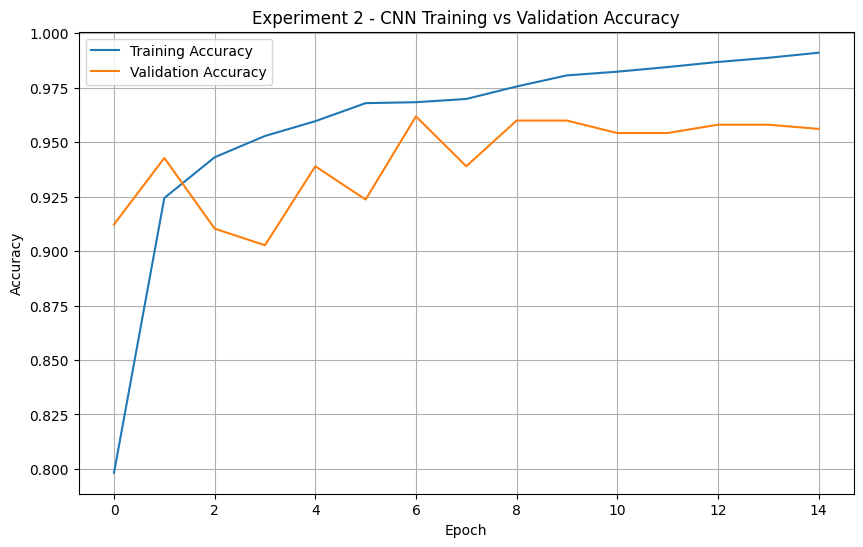

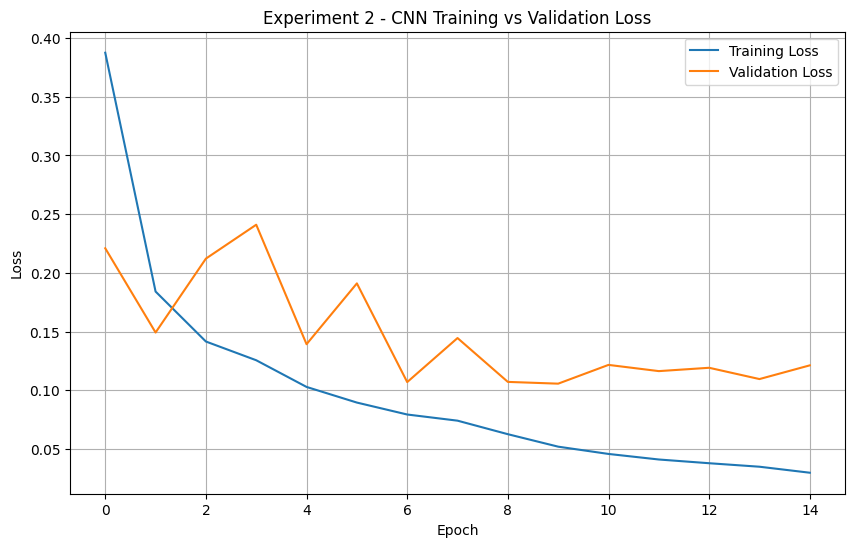

In [42]:
# ================================================================
# EXPERIMENT 2 — TRAINING HISTORY VISUALIZATION
# ================================================================

import matplotlib.pyplot as plt

print("=" * 70)
print("EXPERIMENT 2 - TRAINING HISTORY")
print("=" * 70)

history_data_enhanced = history_enhanced.history

# ------------------------------------------------
# Accuracy
# ------------------------------------------------

plt.figure(figsize=(10, 6))

plt.plot(
    history_data_enhanced["accuracy"],
    label="Training Accuracy"
)

plt.plot(
    history_data_enhanced["val_accuracy"],
    label="Validation Accuracy"
)

plt.title("Experiment 2 - CNN Training vs Validation Accuracy")
plt.xlabel("Epoch")
plt.ylabel("Accuracy")
plt.legend()
plt.grid(True)
plt.show()


# ------------------------------------------------
# Loss
# ------------------------------------------------

plt.figure(figsize=(10, 6))

plt.plot(
    history_data_enhanced["loss"],
    label="Training Loss"
)

plt.plot(
    history_data_enhanced["val_loss"],
    label="Validation Loss"
)

plt.title("Experiment 2 - CNN Training vs Validation Loss")
plt.xlabel("Epoch")
plt.ylabel("Loss")
plt.legend()
plt.grid(True)
plt.show()

EXPERIMENT 2 - CNN CONFUSION MATRIX

Best enhanced CNN model loaded successfully.

Confusion Matrix:
[[150  84]
 [  3 387]]


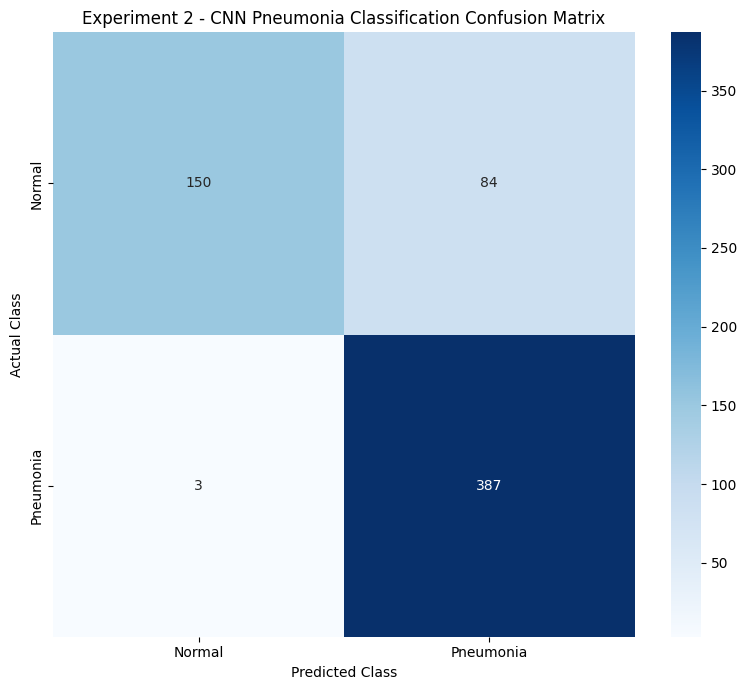

In [43]:
# ================================================================
# EXPERIMENT 2 — CNN CONFUSION MATRIX
# ================================================================

import tensorflow as tf
from sklearn.metrics import confusion_matrix
import seaborn as sns
import matplotlib.pyplot as plt

print("=" * 70)
print("EXPERIMENT 2 - CNN CONFUSION MATRIX")
print("=" * 70)

# Load the best saved Experiment 2 model
enhanced_cnn_model = tf.keras.models.load_model(
    "../models/image_pneumonia_cnn_enhanced_best.keras"
)

print("\nBest enhanced CNN model loaded successfully.")

# Generate predictions
enhanced_test_probabilities = enhanced_cnn_model.predict(
    X_test_enhanced,
    verbose=0
).ravel()

# Default threshold = 0.50
enhanced_test_predictions = (
    enhanced_test_probabilities >= 0.50
).astype(int)

# Confusion matrix
cm_enhanced = confusion_matrix(
    y_test,
    enhanced_test_predictions
)

print("\nConfusion Matrix:")
print(cm_enhanced)

# Plot
plt.figure(figsize=(8, 7))

sns.heatmap(
    cm_enhanced,
    annot=True,
    fmt="d",
    cmap="Blues",
    xticklabels=["Normal", "Pneumonia"],
    yticklabels=["Normal", "Pneumonia"]
)

plt.title("Experiment 2 - CNN Pneumonia Classification Confusion Matrix")
plt.xlabel("Predicted Class")
plt.ylabel("Actual Class")
plt.tight_layout()
plt.show()

EXPERIMENT 2 - CNN ROC CURVE

ROC-AUC: 0.9578


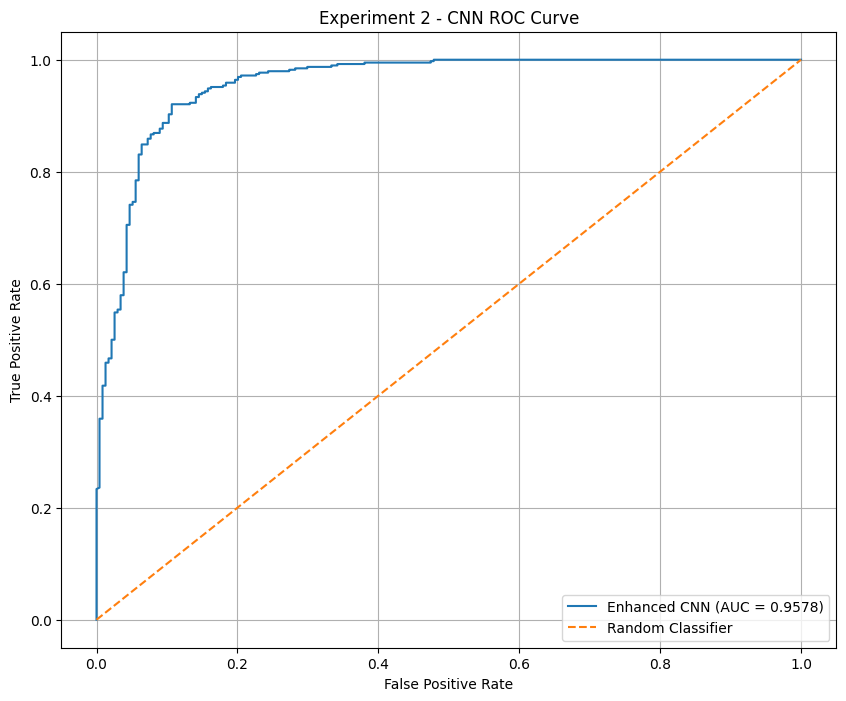

In [44]:
# ================================================================
# EXPERIMENT 2 — CNN ROC CURVE
# ================================================================

from sklearn.metrics import roc_curve, roc_auc_score
import matplotlib.pyplot as plt

print("=" * 70)
print("EXPERIMENT 2 - CNN ROC CURVE")
print("=" * 70)

# Calculate ROC curve
fpr_enhanced, tpr_enhanced, thresholds_enhanced = roc_curve(
    y_test,
    enhanced_test_probabilities
)

# Calculate AUC
auc_enhanced = roc_auc_score(
    y_test,
    enhanced_test_probabilities
)

print(f"\nROC-AUC: {auc_enhanced:.4f}")

# Plot ROC curve
plt.figure(figsize=(10, 8))

plt.plot(
    fpr_enhanced,
    tpr_enhanced,
    label=f"Enhanced CNN (AUC = {auc_enhanced:.4f})"
)

plt.plot(
    [0, 1],
    [0, 1],
    linestyle="--",
    label="Random Classifier"
)

plt.xlabel("False Positive Rate")
plt.ylabel("True Positive Rate")
plt.title("Experiment 2 - CNN ROC Curve")
plt.legend(loc="lower right")
plt.grid(True)
plt.show()

EXPERIMENT 2 - CNN SAMPLE PREDICTIONS

Prediction Results:
----------------------------------------------------------------------
 1. Actual: Pneumonia  | Predicted: Pneumonia  | Confidence: 100.00% | CORRECT
 2. Actual: Normal     | Predicted: Pneumonia  | Confidence:  98.61% | INCORRECT
 3. Actual: Pneumonia  | Predicted: Pneumonia  | Confidence:  99.92% | CORRECT
 4. Actual: Normal     | Predicted: Normal     | Confidence:  99.94% | CORRECT
 5. Actual: Pneumonia  | Predicted: Pneumonia  | Confidence: 100.00% | CORRECT
 6. Actual: Pneumonia  | Predicted: Pneumonia  | Confidence: 100.00% | CORRECT
 7. Actual: Pneumonia  | Predicted: Pneumonia  | Confidence: 100.00% | CORRECT
 8. Actual: Pneumonia  | Predicted: Pneumonia  | Confidence: 100.00% | CORRECT
 9. Actual: Pneumonia  | Predicted: Pneumonia  | Confidence:  99.93% | CORRECT
10. Actual: Normal     | Predicted: Pneumonia  | Confidence:  99.99% | INCORRECT


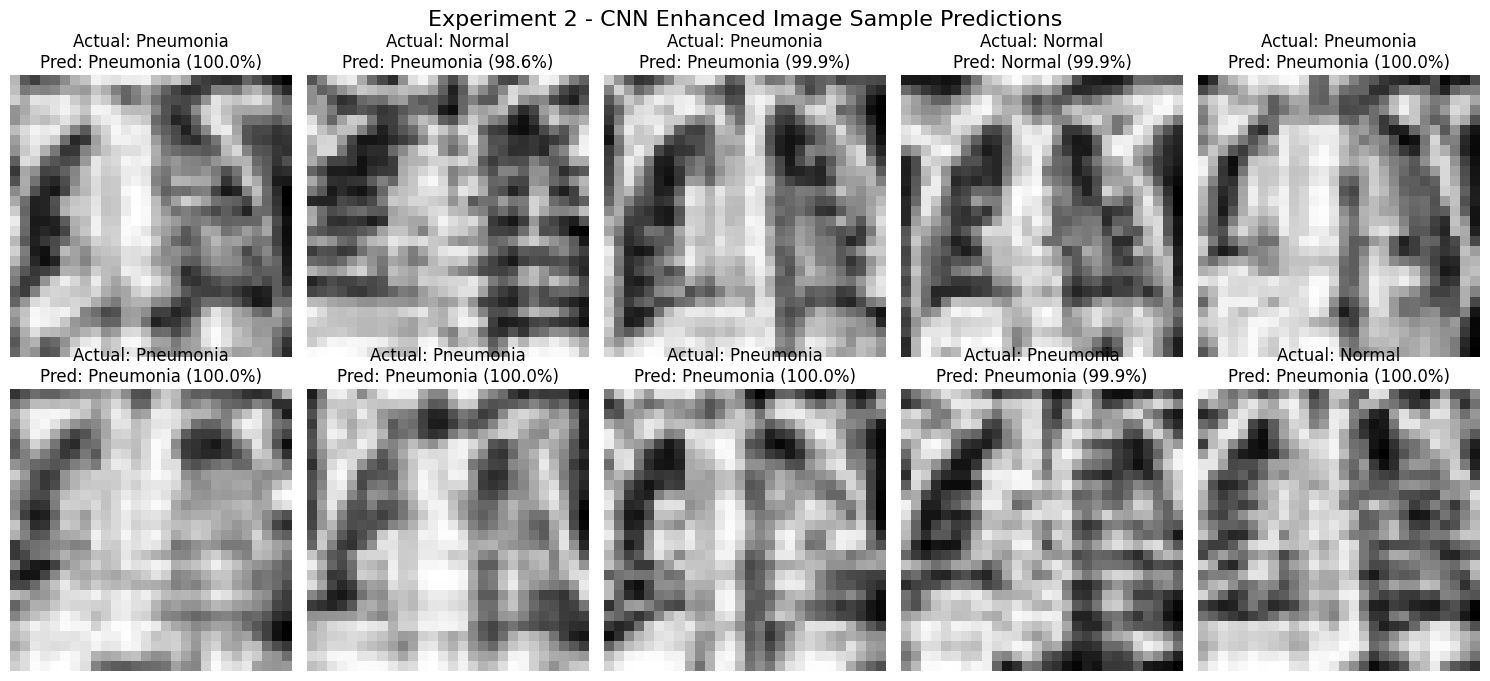

In [45]:
# ================================================================
# EXPERIMENT 2 — CNN SAMPLE PREDICTIONS
# ================================================================

import numpy as np
import matplotlib.pyplot as plt

print("=" * 70)
print("EXPERIMENT 2 - CNN SAMPLE PREDICTIONS")
print("=" * 70)

# Number of samples to display
num_samples = 10

# Use the first 10 test samples
sample_images = X_test_enhanced[:num_samples]
sample_actual = y_test[:num_samples]

# Generate probabilities
sample_probabilities = enhanced_cnn_model.predict(
    sample_images,
    verbose=0
).ravel()

# Use final decision threshold from Experiment 2
sample_predictions = (
    sample_probabilities >= FINAL_THRESHOLD
).astype(int)

class_names = {
    0: "Normal",
    1: "Pneumonia"
}

print("\nPrediction Results:")
print("-" * 70)

for i in range(num_samples):

    actual = int(sample_actual[i])
    predicted = int(sample_predictions[i])
    probability = float(sample_probabilities[i])

    # Confidence of predicted class
    if predicted == 1:
        confidence = probability
    else:
        confidence = 1 - probability

    result = "CORRECT" if actual == predicted else "INCORRECT"

    print(
        f"{i + 1:2d}. "
        f"Actual: {class_names[actual]:10s} | "
        f"Predicted: {class_names[predicted]:10s} | "
        f"Confidence: {confidence * 100:6.2f}% | "
        f"{result}"
    )


# ================================================================
# VISUALIZE SAMPLE PREDICTIONS
# ================================================================

fig, axes = plt.subplots(
    2,
    5,
    figsize=(15, 7)
)

fig.suptitle(
    "Experiment 2 - CNN Enhanced Image Sample Predictions",
    fontsize=16
)

for i, ax in enumerate(axes.flat):

    actual = int(sample_actual[i])
    predicted = int(sample_predictions[i])
    probability = float(sample_probabilities[i])

    if predicted == 1:
        confidence = probability
    else:
        confidence = 1 - probability

    ax.imshow(
        sample_images[i].squeeze(),
        cmap="gray"
    )

    ax.set_title(
        f"Actual: {class_names[actual]}\n"
        f"Pred: {class_names[predicted]} "
        f"({confidence * 100:.1f}%)"
    )

    ax.axis("off")

plt.tight_layout()
plt.show()

In [46]:
# ================================================================
# EXPERIMENT 2 — CNN GRAD-CAM EXPLAINABILITY
# ================================================================

import tensorflow as tf
import numpy as np
import matplotlib.pyplot as plt

print("=" * 70)
print("EXPERIMENT 2 - CNN GRAD-CAM EXPLAINABILITY")
print("=" * 70)

# Use the enhanced CNN model
gradcam_model = enhanced_cnn_model

# Last convolutional layer
last_conv_layer_name_enhanced = "conv2d_5"

last_conv_layer_enhanced = gradcam_model.get_layer(
    last_conv_layer_name_enhanced
)

print("\nLast convolutional layer:",
      last_conv_layer_name_enhanced)

print("Layer output shape:",
      last_conv_layer_enhanced.output.shape)

print("\nGrad-CAM will explain predictions made by the enhanced CNN.")

EXPERIMENT 2 - CNN GRAD-CAM EXPLAINABILITY

Last convolutional layer: conv2d_5
Layer output shape: (None, 7, 7, 128)

Grad-CAM will explain predictions made by the enhanced CNN.


In [47]:
# ================================================================
# GRAD-CAM FUNCTION — KERAS 3 COMPATIBLE
# ================================================================

def make_gradcam_heatmap(
    image,
    model,
    last_conv_layer_name
):
    """
    Generate a Grad-CAM heatmap for a binary CNN classifier.

    This implementation avoids model.output/model.inputs so that
    it works with loaded Keras 3 Sequential models.
    """

    # ------------------------------------------------------------
    # Prepare input
    # ------------------------------------------------------------

    if image.ndim == 3:
        image_batch = np.expand_dims(image, axis=0)
    else:
        image_batch = image

    image_batch = tf.cast(image_batch, tf.float32)

    # ------------------------------------------------------------
    # Create a fresh Functional graph
    # ------------------------------------------------------------

    input_shape = tuple(image_batch.shape[1:])

    inputs = tf.keras.Input(
        shape=input_shape
    )

    x = inputs
    conv_output = None

    # ------------------------------------------------------------
    # Replay the Sequential model layer-by-layer
    # ------------------------------------------------------------

    for layer in model.layers:

        # InputLayer is already represented by `inputs`
        if isinstance(layer, tf.keras.layers.InputLayer):
            continue

        x = layer(x)

        # Save output of requested convolutional layer
        if layer.name == last_conv_layer_name:
            conv_output = x

    # ------------------------------------------------------------
    # Safety check
    # ------------------------------------------------------------

    if conv_output is None:
        raise ValueError(
            f"Could not find convolutional layer: "
            f"{last_conv_layer_name}"
        )

    # Final CNN prediction
    predictions = x

    # ------------------------------------------------------------
    # Create Grad-CAM model
    # ------------------------------------------------------------

    grad_model = tf.keras.Model(
        inputs=inputs,
        outputs=[
            conv_output,
            predictions
        ]
    )

    # ------------------------------------------------------------
    # Calculate gradients
    # ------------------------------------------------------------

    with tf.GradientTape() as tape:

        conv_outputs, predictions = grad_model(
            image_batch,
            training=False
        )

        # Binary classifier:
        # prediction = probability of Pneumonia
        target = predictions[:, 0]

    # Gradient of prediction with respect to feature maps
    grads = tape.gradient(
        target,
        conv_outputs
    )

    if grads is None:
        raise ValueError(
            "Gradients could not be calculated for Grad-CAM."
        )

    # ------------------------------------------------------------
    # Global Average Pooling of gradients
    # ------------------------------------------------------------

    pooled_grads = tf.reduce_mean(
        grads,
        axis=(1, 2)
    )

    # Remove batch dimension
    conv_outputs = conv_outputs[0]
    pooled_grads = pooled_grads[0]

    # ------------------------------------------------------------
    # Weighted feature maps
    # ------------------------------------------------------------

    heatmap = tf.reduce_sum(
        conv_outputs * pooled_grads,
        axis=-1
    )

    # ------------------------------------------------------------
    # ReLU
    # ------------------------------------------------------------

    heatmap = tf.maximum(
        heatmap,
        0
    )

    # ------------------------------------------------------------
    # Normalize
    # ------------------------------------------------------------

    max_value = tf.reduce_max(
        heatmap
    )

    heatmap = tf.where(
        max_value > 0,
        heatmap / max_value,
        heatmap
    )

    return heatmap.numpy()


print("=" * 70)
print("GRAD-CAM FUNCTION — KERAS 3 COMPATIBLE")
print("=" * 70)

print("\nGrad-CAM function created successfully.")
print("Keras 3 compatible implementation.")

GRAD-CAM FUNCTION — KERAS 3 COMPATIBLE

Grad-CAM function created successfully.
Keras 3 compatible implementation.


EXPERIMENT 2 - GRAD-CAM SAMPLE VISUALIZATION


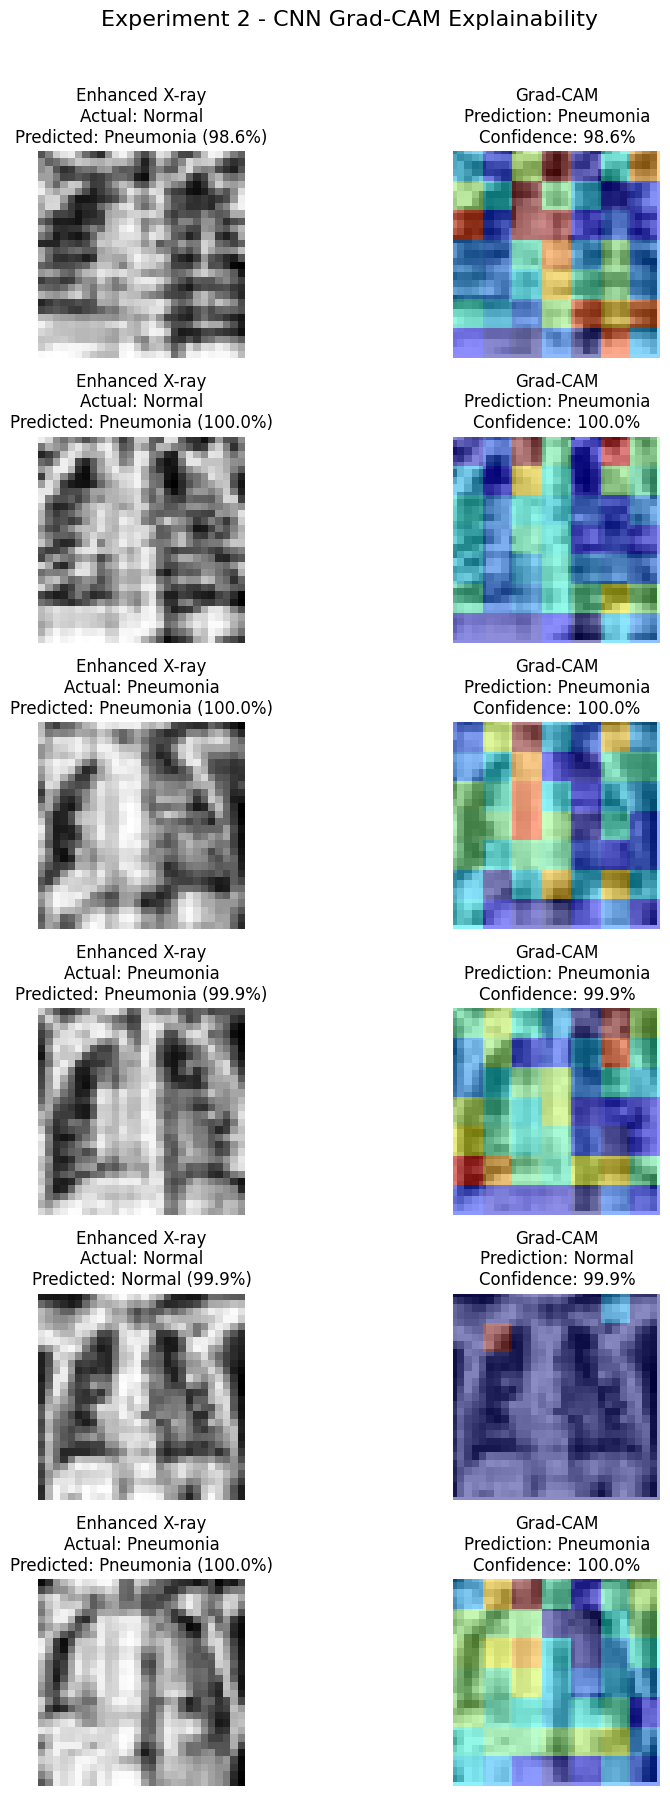

In [48]:
# ================================================================
# EXPERIMENT 2 — GRAD-CAM SAMPLE VISUALIZATION
# ================================================================

print("=" * 70)
print("EXPERIMENT 2 - GRAD-CAM SAMPLE VISUALIZATION")
print("=" * 70)

num_gradcam_samples = 6

class_names = {
    0: "Normal",
    1: "Pneumonia"
}

# ------------------------------------------------
# Select samples
# ------------------------------------------------

# Find both correct and incorrect predictions
correct_indices = np.where(
    sample_predictions == sample_actual
)[0]

incorrect_indices = np.where(
    sample_predictions != sample_actual
)[0]

# Prefer a mixture of correct and incorrect samples
selected_indices = []

# Add incorrect samples first
selected_indices.extend(
    incorrect_indices[:3].tolist()
)

# Then add correct samples
selected_indices.extend(
    correct_indices[:3].tolist()
)

# If fewer than 6 are available, fill from remaining samples
if len(selected_indices) < num_gradcam_samples:

    remaining_indices = [
        i for i in range(num_samples)
        if i not in selected_indices
    ]

    selected_indices.extend(
        remaining_indices[
            :num_gradcam_samples - len(selected_indices)
        ]
    )

selected_indices = selected_indices[:num_gradcam_samples]


# ------------------------------------------------
# Create visualization
# ------------------------------------------------

fig, axes = plt.subplots(
    num_gradcam_samples,
    2,
    figsize=(10, 18)
)

fig.suptitle(
    "Experiment 2 - CNN Grad-CAM Explainability",
    fontsize=16,
    y=0.995
)


for row, i in enumerate(selected_indices):

    image = sample_images[i]
    actual_class = int(sample_actual[i])
    probability = float(sample_probabilities[i])

    predicted_class = int(
        probability >= FINAL_THRESHOLD
    )

    # Confidence of predicted class
    if predicted_class == 1:
        confidence = probability
    else:
        confidence = 1 - probability

    # ------------------------------------------------
    # Generate Grad-CAM
    # ------------------------------------------------

    heatmap = make_gradcam_heatmap(
        image,
        gradcam_model,
        last_conv_layer_name_enhanced
    )

    # ------------------------------------------------
    # Original enhanced image
    # ------------------------------------------------

    axes[row, 0].imshow(
        image.squeeze(),
        cmap="gray"
    )

    axes[row, 0].set_title(
        f"Enhanced X-ray\n"
        f"Actual: {class_names[actual_class]}\n"
        f"Predicted: {class_names[predicted_class]} "
        f"({confidence * 100:.1f}%)"
    )

    axes[row, 0].axis("off")


    # ------------------------------------------------
    # Grad-CAM
    # ------------------------------------------------

    axes[row, 1].imshow(
        image.squeeze(),
        cmap="gray"
    )

    axes[row, 1].imshow(
        heatmap,
        cmap="jet",
        alpha=0.45,
        extent=(
            0,
            image.shape[1],
            image.shape[0],
            0
        )
    )

    axes[row, 1].set_title(
        f"Grad-CAM\n"
        f"Prediction: {class_names[predicted_class]}\n"
        f"Confidence: {confidence * 100:.1f}%"
    )

    axes[row, 1].axis("off")


plt.tight_layout(
    rect=[0, 0, 1, 0.98]
)

plt.show()

# Part 3 — User-Facing Grad-CAM Visualization

The Grad-CAM generated by the CNN provides an explanation of the image regions that influenced the model's prediction. Since the final convolutional feature map has a low spatial resolution, the raw Grad-CAM appears coarse when displayed directly.

In this stage, image-processing operations are applied **only to the Grad-CAM visualization**. The model input, prediction, and evaluation results remain unchanged.

The visualization pipeline applies heatmap upsampling, Gaussian smoothing, normalization, and transparent overlay blending to produce a clearer user-facing explanation.

PART 3 - ENHANCED GRAD-CAM VISUALIZATION


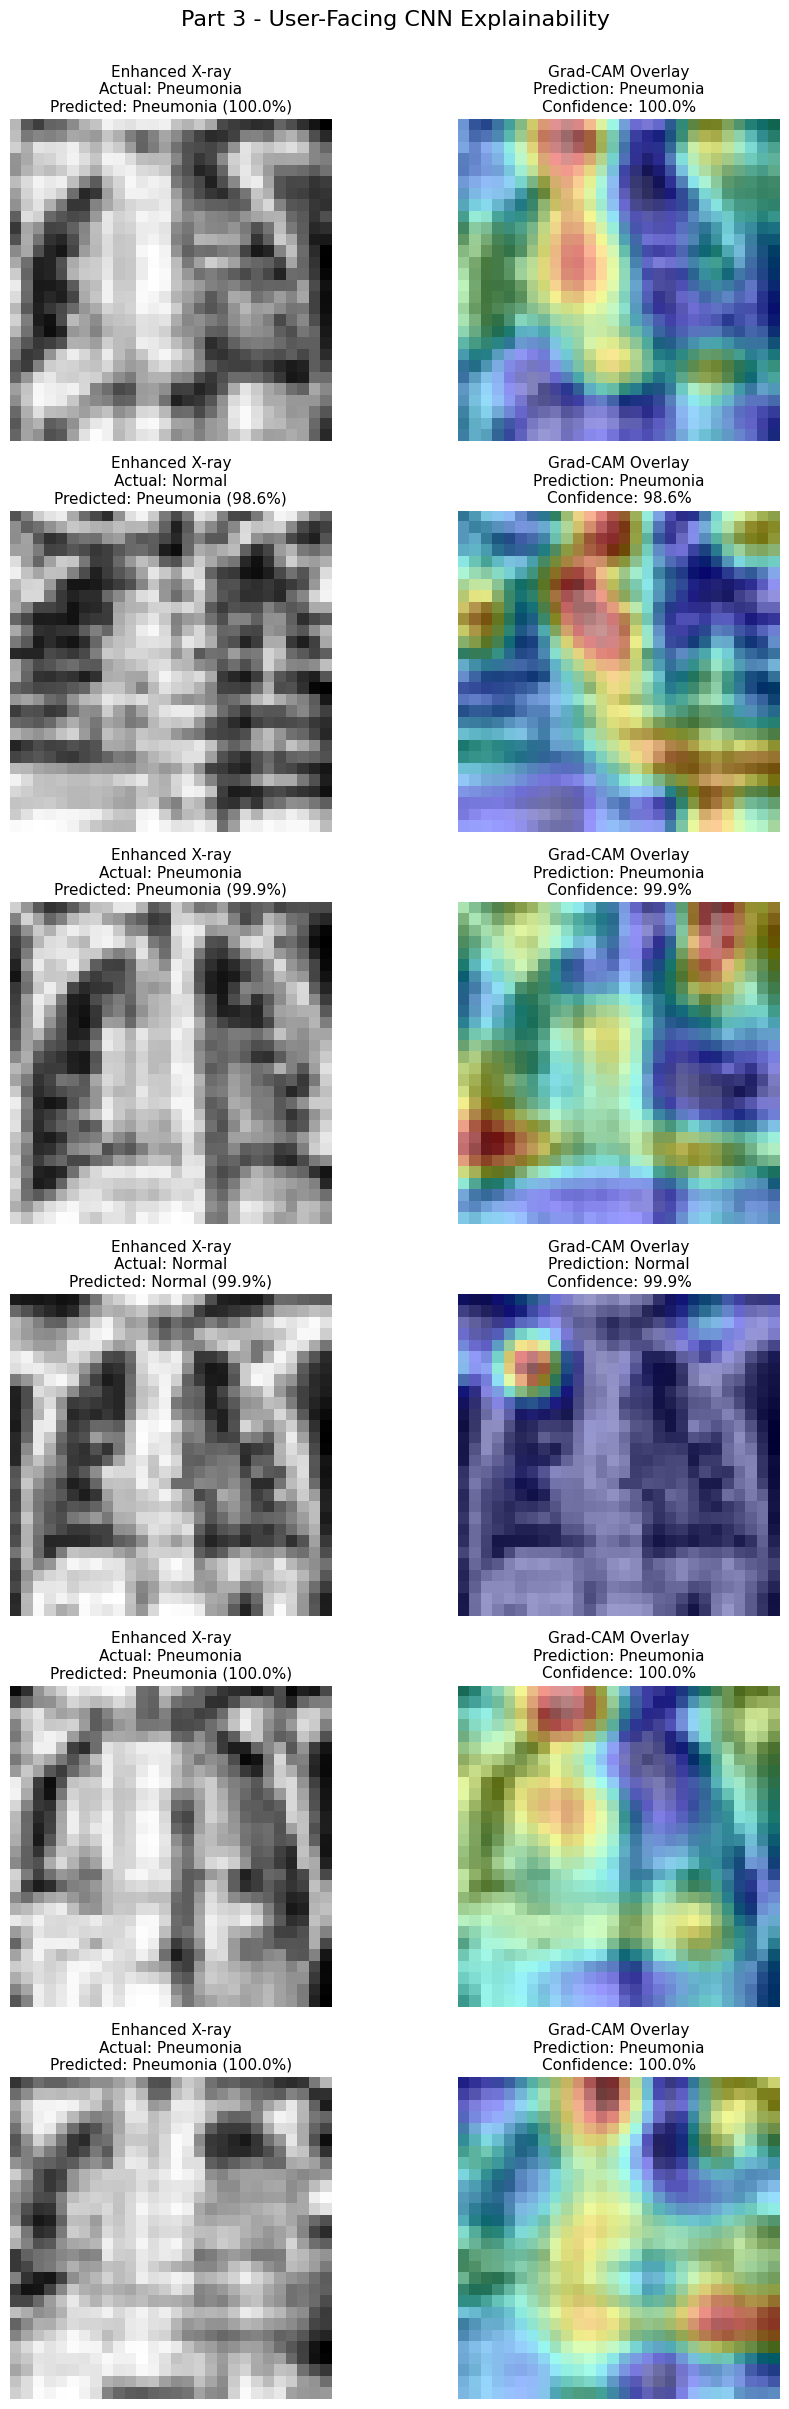


Grad-CAM visualization completed successfully.
Visualization-only image processing applied:
  - Bicubic heatmap upsampling
  - Gaussian heatmap smoothing
  - Heatmap normalization
  - Transparent heatmap overlay

Model predictions and evaluation metrics remain unchanged.


In [49]:
# ================================================================
# PART 3 - USER-FACING GRAD-CAM VISUALIZATION
# ================================================================

print("=" * 70)
print("PART 3 - ENHANCED GRAD-CAM VISUALIZATION")
print("=" * 70)

import numpy as np
import matplotlib.pyplot as plt

from skimage.transform import resize
from skimage.filters import gaussian


# ------------------------------------------------
# Visualization settings
# ------------------------------------------------

num_display_samples = min(6, len(sample_images))

# Transparency of Grad-CAM overlay
overlay_alpha = 0.40

# Gaussian smoothing strength
heatmap_sigma = 1.0


# ------------------------------------------------
# Create enhanced Grad-CAM overlay
# ------------------------------------------------

def create_gradcam_overlay(image, heatmap):
    """
    Create a smoother and more interpretable Grad-CAM overlay.

    This function is used ONLY for visualization.
    It does not modify the image used by the CNN.
    """

    # Remove unnecessary dimensions
    base_image = np.squeeze(image).astype(np.float32)

    # Normalize image for display
    base_min = base_image.min()
    base_max = base_image.max()

    if base_max > base_min:
        base_image = (base_image - base_min) / (base_max - base_min)
    else:
        base_image = np.zeros_like(base_image)

    # Resize Grad-CAM heatmap to original image size
    resized_heatmap = resize(
        heatmap,
        base_image.shape,
        order=3,                 # Bicubic interpolation
        mode="reflect",
        anti_aliasing=True
    )

    # Smooth the heatmap
    smoothed_heatmap = gaussian(
        resized_heatmap,
        sigma=heatmap_sigma
    )

    # Normalize heatmap
    heatmap_min = smoothed_heatmap.min()
    heatmap_max = smoothed_heatmap.max()

    if heatmap_max > heatmap_min:
        smoothed_heatmap = (
            smoothed_heatmap - heatmap_min
        ) / (heatmap_max - heatmap_min)
    else:
        smoothed_heatmap = np.zeros_like(smoothed_heatmap)

    return base_image, smoothed_heatmap


# ------------------------------------------------
# Generate visualization
# ------------------------------------------------

fig, axes = plt.subplots(
    num_display_samples,
    2,
    figsize=(10, 4 * num_display_samples)
)

# Handle case of only one sample
if num_display_samples == 1:
    axes = np.expand_dims(axes, axis=0)


class_names = {
    0: "Normal",
    1: "Pneumonia"
}


for i in range(num_display_samples):

    image = sample_images[i]
    actual_class = int(sample_actual[i])
    probability = float(sample_probabilities[i])

    predicted_class = int(
        probability >= FINAL_THRESHOLD
    )

    confidence = (
        probability
        if predicted_class == 1
        else 1 - probability
    )

    # ------------------------------------------------
    # Generate Grad-CAM using existing function
    # ------------------------------------------------

    heatmap = make_gradcam_heatmap(
        image,
        gradcam_model,
        last_conv_layer_name_enhanced
    )

    # ------------------------------------------------
    # Prepare image + heatmap for visualization
    # ------------------------------------------------

    display_image, smooth_heatmap = create_gradcam_overlay(
        image,
        heatmap
    )

    # ------------------------------------------------
    # Original enhanced X-ray
    # ------------------------------------------------

    axes[i, 0].imshow(
        display_image,
        cmap="gray"
    )

    axes[i, 0].set_title(
        f"Enhanced X-ray\n"
        f"Actual: {class_names[actual_class]}\n"
        f"Predicted: {class_names[predicted_class]} "
        f"({confidence * 100:.1f}%)",
        fontsize=11
    )

    axes[i, 0].axis("off")

    # ------------------------------------------------
    # Grad-CAM overlay
    # ------------------------------------------------

    axes[i, 1].imshow(
        display_image,
        cmap="gray"
    )

    axes[i, 1].imshow(
        smooth_heatmap,
        cmap="jet",
        alpha=overlay_alpha,
        vmin=0,
        vmax=1
    )

    axes[i, 1].set_title(
        f"Grad-CAM Overlay\n"
        f"Prediction: {class_names[predicted_class]}\n"
        f"Confidence: {confidence * 100:.1f}%",
        fontsize=11
    )

    axes[i, 1].axis("off")


plt.suptitle(
    "Part 3 - User-Facing CNN Explainability",
    fontsize=16,
    y=1.002
)

plt.tight_layout()
plt.show()


print("\nGrad-CAM visualization completed successfully.")
print("Visualization-only image processing applied:")
print("  - Bicubic heatmap upsampling")
print("  - Gaussian heatmap smoothing")
print("  - Heatmap normalization")
print("  - Transparent heatmap overlay")

print("\nModel predictions and evaluation metrics remain unchanged.")

# Final Comparison — Baseline CNN vs Image-Processing Enhanced CNN

The two CNN experiments are compared to determine whether image-processing enhancement improves pneumonia classification performance.

Experiment 1 represents the baseline CNN trained using the original normalized PneumoniaMNIST images.

Experiment 2 represents the CNN trained using images processed with contrast enhancement, CLAHE, mild Gaussian denoising, and normalization.

Performance is evaluated using Accuracy, Precision, Recall, F1-score, and ROC-AUC. Since threshold-dependent metrics can change with the classification threshold, both default-threshold performance and validation-selected operating thresholds are considered.

Grad-CAM visualizations are treated separately as an explainability component and do not affect model performance.

FINAL COMPARISON - BASELINE CNN VS ENHANCED CNN

Performance Comparison:


,Metric,Baseline CNN,Enhanced CNN (Threshold 0.50),Enhanced CNN (Threshold 0.20)
0,Accuracy,87.18%,85.58%,81.57%
1,Precision,83.99%,82.19%,77.45%
2,Recall,98.21%,98.21%,99.49%
3,F1 Score,90.54%,89.49%,87.09%
4,AUC,94.04%,95.78%,95.78%



AUC Improvement:
Baseline AUC : 0.9404
Enhanced AUC : 0.9578
Absolute improvement : +0.0174
Percentage-point improvement : +1.74 percentage points

Default Threshold (0.50) Differences:
Accuracy  : -1.60 percentage points
Precision : -1.80 percentage points
Recall    : +0.00 percentage points
F1 Score  : -1.05 percentage points
AUC       : +1.74 percentage points


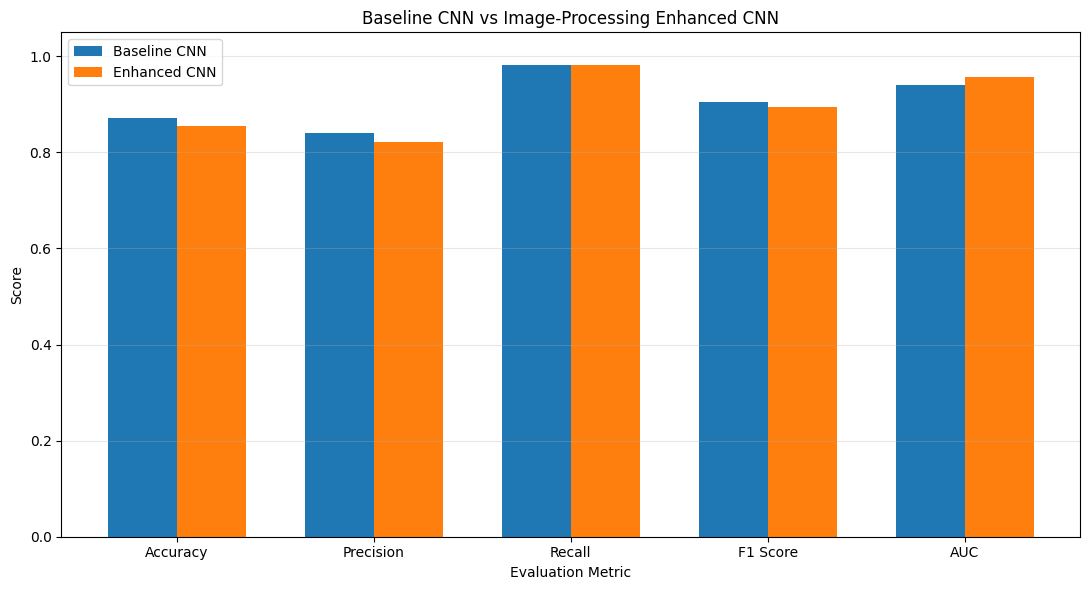


COMPARISON COMPLETED


In [1]:
# ================================================================
# FINAL COMPARISON - BASELINE CNN VS ENHANCED CNN
# ================================================================

print("=" * 70)
print("FINAL COMPARISON - BASELINE CNN VS ENHANCED CNN")
print("=" * 70)

import pandas as pd
import matplotlib.pyplot as plt
import numpy as np


# ------------------------------------------------
# Baseline CNN results
# ------------------------------------------------

baseline_results = {
    "Accuracy": 0.8718,
    "Precision": 0.8399,
    "Recall": 0.9821,
    "F1 Score": 0.9054,
    "AUC": 0.9404
}


# ------------------------------------------------
# Enhanced CNN - default threshold (0.50)
# ------------------------------------------------

enhanced_default_results = {
    "Accuracy": 0.8558,
    "Precision": 0.8219,
    "Recall": 0.9821,
    "F1 Score": 0.8949,
    "AUC": 0.9578
}


# ------------------------------------------------
# Enhanced CNN - selected threshold (0.20)
# ------------------------------------------------

enhanced_selected_results = {
    "Accuracy": 0.8157,
    "Precision": 0.7745,
    "Recall": 0.9949,
    "F1 Score": 0.8709,
    "AUC": 0.9578
}


# ------------------------------------------------
# Create comparison table
# ------------------------------------------------

comparison_df = pd.DataFrame({
    "Metric": list(baseline_results.keys()),
    "Baseline CNN": list(baseline_results.values()),
    "Enhanced CNN (Threshold 0.50)": list(
        enhanced_default_results.values()
    ),
    "Enhanced CNN (Threshold 0.20)": list(
        enhanced_selected_results.values()
    )
})


# Convert metrics to percentage for display
display_df = comparison_df.copy()

for column in display_df.columns[1:]:
    display_df[column] = (
        display_df[column] * 100
    ).round(2).astype(str) + "%"


print("\nPerformance Comparison:")
display(display_df)


# ------------------------------------------------
# Calculate improvement in AUC
# ------------------------------------------------

auc_change = (
    enhanced_default_results["AUC"]
    - baseline_results["AUC"]
)

print("\nAUC Improvement:")
print(
    f"Baseline AUC : "
    f"{baseline_results['AUC']:.4f}"
)

print(
    f"Enhanced AUC : "
    f"{enhanced_default_results['AUC']:.4f}"
)

print(
    f"Absolute improvement : "
    f"{auc_change:+.4f}"
)

print(
    f"Percentage-point improvement : "
    f"{auc_change * 100:+.2f} percentage points"
)


# ------------------------------------------------
# Metric differences at default threshold
# ------------------------------------------------

print("\nDefault Threshold (0.50) Differences:")

for metric in baseline_results:

    difference = (
        enhanced_default_results[metric]
        - baseline_results[metric]
    )

    print(
        f"{metric:10s}: "
        f"{difference * 100:+.2f} percentage points"
    )


# ------------------------------------------------
# Visualization
# ------------------------------------------------

metrics = [
    "Accuracy",
    "Precision",
    "Recall",
    "F1 Score",
    "AUC"
]

baseline_values = [
    baseline_results[m]
    for m in metrics
]

enhanced_values = [
    enhanced_default_results[m]
    for m in metrics
]

x = np.arange(len(metrics))
width = 0.35

fig, ax = plt.subplots(
    figsize=(11, 6)
)

ax.bar(
    x - width / 2,
    baseline_values,
    width,
    label="Baseline CNN"
)

ax.bar(
    x + width / 2,
    enhanced_values,
    width,
    label="Enhanced CNN"
)

ax.set_ylabel("Score")
ax.set_xlabel("Evaluation Metric")
ax.set_title(
    "Baseline CNN vs Image-Processing Enhanced CNN"
)

ax.set_xticks(x)
ax.set_xticklabels(metrics)

ax.set_ylim(0, 1.05)

ax.legend()

ax.grid(
    axis="y",
    alpha=0.3
)

plt.tight_layout()
plt.show()


print("\n" + "=" * 70)
print("COMPARISON COMPLETED")
print("=" * 70)

# Final Experimental Findings

The comparison between the baseline CNN and the image-processing-enhanced CNN produced the following findings:

- The baseline CNN achieved an accuracy of 87.18% and ROC-AUC of 94.04%.
- The image-processing-enhanced CNN achieved an accuracy of 85.58% and ROC-AUC of 95.78% at the default classification threshold of 0.50.
- Image-processing enhancement therefore improved ROC-AUC by 1.74 percentage points, indicating improved overall discrimination between Normal and Pneumonia classes.
- However, accuracy, precision, and F1-score decreased slightly compared with the baseline CNN, while recall remained unchanged at 98.21%.
- Threshold analysis showed that lowering the enhanced CNN decision threshold to 0.20 increased Pneumonia recall to 99.49%, but reduced accuracy to 81.57% and precision to 77.45%.
- This demonstrates the trade-off between sensitivity and false-positive predictions when changing the classification threshold.

The experiments therefore show that image enhancement can affect different aspects of model performance differently. In this study, enhancement improved the model's overall ranking/discrimination ability (ROC-AUC), but did not improve default-threshold classification accuracy.

Grad-CAM was subsequently used as an explainability technique. Display-only image-processing operations were applied to the Grad-CAM visualization to improve readability without modifying the CNN predictions or evaluation metrics.